# PHASE 1 — FDIC Full-History Acquisition & Bronze (Consolidated)

**Source:** `01_phase1_STANDALONE_FIXED(3).ipynb` with selected verified safeguards from the aligned notebook. **Complete source scope:** 1984Q1–2026Q2 (170 quarters; actual observed rows determined by live/cached FDIC records). **Never use the deprecated Phase 0 full-history protocol.** Train/validation/test and event labels belong to later phases.

Data engineering and provenance checks do NOT certify FDIC snapshot isolation or point-in-time release vintages.

## 0 — Reproducibility, inputs and execution policy

**Acceptance conditions:** The Phase 0 JSON count matches its field list, every code is unique, identifiers are present, and the original schema/research fingerprints match if their files are available. Fail closed rather than silently reverting to 48 fields.

**Acquisition modes:** `full` downloads/resumes all 170 quarters; `pilot` tests 2023Q1–2023Q4. A distinct Phase-0 field-contract hash is used in both Raw and Bronze paths, preventing collision with older datasets. First run can involve substantial FDIC traffic: use `pilot` to smoke-test before `full`.

### 0.0 — Environment & Phase-0 contract preflight

**Run this cell first.** If it fails, run Phase 0 Section 9.1–9.8 to export the field handoff or set `ROOT_OVERRIDE` to the actual repository folder. The notebook deliberately **never guesses the number of fields** or silently falls back to 48 columns.

**Why standalone?** The previous notebook imported `fdic_handoff_pipeline` from `src/phase1/` but the standalone `.ipynb` download did not contain that file. In this corrected version, all helpers are visible in bounded code cells below, making module installation unnecessary.

In [1]:
# 0.0 — Fail-fast root discovery for Phase-0 full-history bundle
from pathlib import Path
ROOT_OVERRIDE=None  # set explicit repository directory only if notebook is outside the repository
PROJECT_NAME='BFT65B-Bank-Failure-EWS'
HANDOFF_REL=Path('docs/phase0_phase1_field_handoff_v2.json')
SCOPE_REL=Path('docs/phase0_data_scope_contract.json')
BUNDLE_REL=Path('docs/phase0_artifact_bundle_manifest.json')
REQUIRED_PHASE0_FILES=[HANDOFF_REL,SCOPE_REL,BUNDLE_REL,Path('docs/phase0_all_fdic_financial_fields_v2.csv'),
                       Path('docs/phase0_phase1_selected_fields_v2.csv'),
                       Path('docs/phase0_ALL_field_scores_v2.csv'),
                       Path('docs/research_matrix.csv'),Path('docs/fdic_financial_schema.yaml')]
cwd=Path.cwd().resolve()
roots=[cwd,*cwd.parents]
candidates=([Path(ROOT_OVERRIDE).expanduser().resolve()] if ROOT_OVERRIDE else
            list(dict.fromkeys(roots+[p/PROJECT_NAME for p in roots])))
ROOT=next((p for p in candidates if (p/HANDOFF_REL).is_file() and (p/SCOPE_REL).is_file()),None)
if ROOT is None:
    raise FileNotFoundError('Full-history Phase 0 outputs are missing. Run Phase 0 (full history) first; '
                            f'expected {HANDOFF_REL} and {SCOPE_REL} under repository root; cwd={cwd}')
missing=[str(ROOT/p) for p in REQUIRED_PHASE0_FILES if not (ROOT/p).is_file()]
if missing:raise FileNotFoundError('Incomplete Phase0 artifact bundle: '+', '.join(missing))
print('Project repository:',ROOT,'| source scope contract:',ROOT/SCOPE_REL)

Project repository: C:\học tập\kì 7\Big data\Final\Bản nháp | source scope contract: C:\học tập\kì 7\Big data\Final\Bản nháp\docs\phase0_data_scope_contract.json


### 0.A — Auditable inline pipeline helpers

The seven source sections below are the same project helper functions previously stored in `src/phase1/fdic_handoff_pipeline.py`. They remain separated by responsibility (API, keys, Raw, Bronze and source references). These cells define functions; **they do not call the FDIC API or write source data**. You can collapse this subsection after auditing it.

**0.A1 — Imports, field contract, SHA-256 and handoff validation**. Đây là mã nguồn helper nội tuyến; có thể đọc, kiểm tra và chạy riêng, không cần file `.py` bên ngoài.

In [2]:
# 0.A1 — Imports, field contract, SHA-256 and handoff validation
"""FDIC Phase-1: immutable, Phase-0-handoff-driven acquisition and storage.

This module intentionally does not construct financial ratios, failure labels, or ML features.
Every API snapshot is tied to the exact Phase-0 fields_to_request contract.
"""
from __future__ import annotations

import hashlib
import json
import math
import os
import re
import tempfile
import time
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Callable

import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

API_BASE = 'https://api.fdic.gov/banks'
KEYS = ('CERT', 'REPDTE')
DEFAULT_FAILURE_FIELDS = ['CERT','NAME','CITYST','FAILDATE','FAILYR','COST','QBFASSET','QBFDEP','RESTYPE','RESTYPE1']
DEFAULT_INSTITUTION_FIELDS = ['CERT','NAME','STNAME','BKCLASS','ACTIVE','ESTYMD','ENDEFYMD','CHANGEC1','INSDATE']
LEAKAGE_RE = re.compile(r'(^FAIL|FAILURE|FAILED|RECEIVERSHIP|LIQUIDATION|ACTEVT|ENDEFYMD|ENDDATE)', re.I)


def utcnow() -> str:
    return datetime.now(timezone.utc).isoformat()


def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()


def contract_hash(fields: list[str]) -> str:
    return hashlib.sha256(json.dumps(fields, separators=(',', ':')).encode('utf-8')).hexdigest()[:16]


def load_handoff(path: Path, root: Path | None = None) -> dict:
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(
            f'Missing Phase-0 handoff: {path}. Run Section 9 and 10 of '
            '00_phase0_AUDITABLE_ANNOTATED.ipynb first; never fall back to the old 48 fields.')
    data = json.loads(path.read_text(encoding='utf-8'))
    fields = data.get('fields_to_request')
    if not isinstance(fields, list) or len(fields) < 3:
        raise ValueError('Phase-0 fields_to_request missing/empty')
    if any(not isinstance(x, str) or not re.fullmatch(r'[A-Z][A-Z0-9_]*', x) for x in fields):
        raise ValueError('Invalid field codes in Phase-0 handoff')
    if len(fields) != len(set(fields)):
        raise ValueError('Duplicate codes in Phase-0 handoff')
    if not set(KEYS).issubset(fields):
        raise ValueError('CERT and REPDTE must be present')
    if len(fields) != data.get('n_fields_to_request'):
        raise ValueError('Phase-0 n_fields_to_request differs from actual code list')
    if any(LEAKAGE_RE.search(x) for x in fields if x not in KEYS):
        raise ValueError('A potential event/post-failure field appears in predictor acquisition list')
    if data.get('selection_status', '').startswith('PROVISIONAL'):
        pass # explicitly retain provisional status in user-facing reporting
    if root is not None:
        schema = Path(root)/'docs/fdic_financial_schema.yaml'
        expected = data.get('schema_sha256')
        if expected and schema.exists() and sha256(schema) != expected:
            raise ValueError('Official FDIC schema has changed since Phase-0 handoff. Re-run Phase 0 before acquisition.')
        r = Path(root)/'docs/research_matrix.csv'
        expected_r = data.get('research_sha256')
        if expected_r and r.exists() and sha256(r) != expected_r:
            raise ValueError('Research matrix differs from Phase-0 selection provenance. Re-run Phase 0.')
    data['field_contract_hash'] = contract_hash(fields)
    return data




**0.A2 — API batching, client, response decoding and pagination**. Đây là mã nguồn helper nội tuyến; có thể đọc, kiểm tra và chạy riêng, không cần file `.py` bên ngoài.

In [3]:
# 0.A2 — API batching, client, response decoding and pagination
def field_batches(fields: list[str], nonkey_per_batch: int = 30) -> list[list[str]]:
    """Each independently paginated API request contains both join keys."""
    if nonkey_per_batch < 1:
        raise ValueError('nonkey_per_batch must be positive')
    extras = [f for f in fields if f not in KEYS]
    return [list(KEYS) + extras[i:i + nonkey_per_batch]
            for i in range(0, len(extras), nonkey_per_batch)] or [list(KEYS)]


class FDICClient:
    def __init__(self, base: str = API_BASE, timeout: float = 90, session=None):
        self.base = base.rstrip('/')
        self.timeout = timeout
        self.session = session or requests.Session()
        if session is None:
            retry = Retry(total=5, backoff_factor=1.2, status_forcelist=[429,500,502,503,504],
                          respect_retry_after_header=True, allowed_methods=['GET'])
            self.session.mount('https://', HTTPAdapter(max_retries=retry))

    def get_page(self, endpoint: str, params: dict) -> dict:
        response = self.session.get(f'{self.base}/{endpoint}', params=params, timeout=self.timeout)
        response.raise_for_status()
        payload = response.json()
        if not isinstance(payload, dict) or not isinstance(payload.get('data'), list):
            raise ValueError(f'Invalid FDIC {endpoint} API response shape')
        return payload


def decode_rows(payload: dict) -> list[dict]:
    output = []
    for item in payload.get('data', []):
        row = item.get('data', item) if isinstance(item, dict) else None
        if not isinstance(row, dict):
            raise ValueError('FDIC data row must be an object')
        output.append(row)
    return output


def fetch_pages(client, endpoint: str, fields: list[str], *, filters: str | None = None,
                page_size: int = 1000, sort_by: str = 'CERT', max_pages: int = 200,
                single_page_only: bool = False) -> tuple[list[dict], dict]:
    """Count/page SHA/overlap checks. Strict unique-key order for financials and institutions.
    Does NOT provide snapshot isolation across FDIC API requests."""
    if page_size < 1 or page_size > 10000:
        raise ValueError('page_size outside 1..10000')
    if sort_by not in ('CERT', 'FAILDATE'):
        raise ValueError('Unknown sort_by: use only audited sort keys')
    records, pages, expected = [], [], None
    seen_row_fingerprints = set()
    seen_sort_keys = set()
    previous_sort_key = None
    strict_cert_key = sort_by == 'CERT' and endpoint in ('financials','institutions')
    stable_sort_warning = not strict_cert_key
    offset = 0
    while True:
        params = {'fields': ','.join(fields), 'limit': page_size, 'offset': offset,
                  'sort_by': sort_by, 'sort_order': 'ASC', 'format': 'json'}
        if filters:
            params['filters'] = filters
        response = client.get_page(endpoint, params)
        meta = response.get('meta') or {}
        if 'total' not in meta:
            raise ValueError('FDIC response lacks meta.total; completeness cannot be certified')
        total = int(meta['total'])
        if total < 0 or (expected is not None and total != expected):
            raise ValueError(f'API total changed during pagination: {expected} → {total}')
        expected = total
        if single_page_only and total > page_size:
            raise ValueError(f'{endpoint} total {total} > single-page cap {page_size}: use source sharding')
        block = decode_rows(response)
        if total > 0 and not block:
            raise ValueError('Premature empty API page')
        if len(block) > page_size:
            raise ValueError('API returned more rows than requested page size')
        if strict_cert_key:
            # Financials is filtered to one quarter by quarter_extract; institutions
            # is expected to have one row per CERT. Any duplicates invalidate the proof.
            current = []
            for row in block:
                cert = row.get('CERT')
                if cert is None:raise ValueError('API page missing CERT for unique-key pagination')
                key = int(normalize_key(cert))
                if key in seen_sort_keys:
                    raise ValueError(f'Duplicate unique CERT across API pages: {cert}')
                current.append(key)
            if current != sorted(set(current)):
                raise ValueError(f'Non-monotone or duplicated CERT values within {endpoint} page')
            if previous_sort_key is not None and current and current[0] <= previous_sort_key:
                raise ValueError('Non-monotone CERT across API pagination boundary')
            seen_sort_keys.update(current)
            if current:previous_sort_key=current[-1]

        page_bytes = json.dumps(block,sort_keys=True,default=str,separators=(',',':')).encode()
        page_hash = hashlib.sha256(page_bytes).hexdigest()
        page_fingerprints = [hashlib.sha256(json.dumps(row,sort_keys=True,default=str,
                             separators=(',',':')).encode()).hexdigest() for row in block]
        if len(set(page_fingerprints)) != len(page_fingerprints):
            raise ValueError(f'Duplicate complete rows inside {endpoint} page at offset {offset}')
        overlap = set(page_fingerprints) & seen_row_fingerprints
        if overlap:
            raise ValueError(f'Overlapping complete rows across {endpoint} API pages at offset {offset}')
        seen_row_fingerprints.update(page_fingerprints)
        records.extend(block)
        pages.append({'offset': offset, 'limit':page_size, 'count': len(block),
                      'page_sha256':page_hash, 'first_sort_value':block[0].get(sort_by) if block else None,
                      'last_sort_value':block[-1].get(sort_by) if block else None,
                      'api_total':total, 'retrieved_at_utc':utcnow()})
        if len(records) >= total:
            break
        if len(pages) >= max_pages:
            raise ValueError('max_pages exceeded: increase deliberate bound or page size')
        offset += len(block)
    if len(records) != expected:
        raise ValueError(f'Incomplete pagination: {len(records)} != API total {expected}')
    return records, {'endpoint': endpoint, 'source_url': f'{client.base}/{endpoint}',
                     'filters': filters, 'sort_by': sort_by, 'page_size': page_size,
                     'fields_requested': fields, 'api_total': expected,
                     'pages': len(pages), 'page_details': pages, 'fetched_utc': utcnow(),
                     'sort_key_uniqueness_verified':bool(strict_cert_key),
                     'pagination_consistency_status': ('COUNT_AND_ROW_OVERLAP_ONLY_NONUNIQUE_SORT'
                         if stable_sort_warning else 'COUNT_SHA_UNIQUE_CERT_MONOTONE_VERIFIED_NOT_SNAPSHOT_ISOLATED'),
                     'snapshot_isolation_verified':False}

**0.A3 — Identifier and quarter normalization; multi-batch stitching**. Đây là mã nguồn helper nội tuyến; có thể đọc, kiểm tra và chạy riêng, không cần file `.py` bên ngoài.

In [4]:
# 0.A3 — Identifier and quarter normalization; multi-batch stitching
def normalize_key(value) -> str:
    if value is None or pd.isna(value):
        raise ValueError('Missing CERT')
    x = str(value).strip()
    if re.fullmatch(r'\d+\.0+', x):
        x = x.split('.')[0]
    if not re.fullmatch(r'\d+', x):
        raise ValueError(f'Invalid CERT: {x!r}')
    return str(int(x))


def normalize_repdte(value) -> str:
    if value is None or pd.isna(value):
        raise ValueError('Missing REPDTE')
    raw = str(value).strip()
    if re.fullmatch(r'\d{4}-\d{2}-\d{2}', raw):
        d = pd.to_datetime(raw, format='%Y-%m-%d', errors='raise')
    elif re.fullmatch(r'\d{8}', raw):
        d = pd.to_datetime(raw, format='%Y%m%d', errors='raise')
    else:
        raise ValueError(f'Invalid reporting date {raw!r}')
    return d.strftime('%Y%m%d')


def quarter_end(q: str) -> str:
    return pd.Period(q, freq='Q').end_time.strftime('%Y%m%d')


def quarter_extract(client, quarter: str, fields: list[str], *, page_size: int = 1000,
                    fields_per_batch: int = 30, sleep_between_batches: float = 0) -> tuple[pd.DataFrame, dict]:
    """Fetch all independently-paginated field groups; refuse incomplete/misaligned joins."""
    date = quarter_end(quarter)
    batches = field_batches(fields, nonkey_per_batch=fields_per_batch)
    frame = None
    metadata = []
    shared_total = None
    reference_keyset = None
    for index, group_fields in enumerate(batches, 1):
        rows, meta = fetch_pages(client, 'financials', group_fields, filters=f'REPDTE:{date}',
                                 page_size=page_size, sort_by='CERT')
        data = pd.DataFrame.from_records(rows)
        for key in KEYS:
            if key not in data.columns:
                if len(rows) == 0:
                    data[key] = pd.Series(dtype='string')
                else:
                    raise ValueError(f'{quarter}: batch {index} lacks join key {key}')
        data['CERT'] = data['CERT'].map(normalize_key)
        data['REPDTE'] = data['REPDTE'].map(normalize_repdte)
        if len(data) and not data['REPDTE'].eq(date).all():
            raise ValueError(f'{quarter}: API rows outside quarter')
        if data.duplicated(list(KEYS)).any():
            raise ValueError(f'{quarter}: duplicate CERT-REPDTE in API batch {index}')
        # FDIC can omit a column entirely if all observations are null.
        for field in group_fields:
            if field not in data.columns:
                data[field] = pd.NA
        data = data[group_fields]
        keys = set(map(tuple, data[list(KEYS)].itertuples(index=False, name=None)))
        if shared_total is None:
            shared_total, reference_keyset = meta['api_total'], keys
        elif shared_total != meta['api_total'] or keys != reference_keyset:
            raise ValueError(f'{quarter}: batch key set/API totals differ; do not silently join partial vintage')
        frame = data if frame is None else frame.merge(data.drop(columns=[]), on=list(KEYS),
                                                       how='inner', validate='one_to_one',sort=False)
        metadata.append({'group':index,'requested_fields':group_fields,'api_total':meta['api_total'],
                         'pages':meta['pages'],'page_details':meta['page_details']})
        if sleep_between_batches and index < len(batches):
            time.sleep(sleep_between_batches)
    if len(frame) != shared_total:
        raise ValueError(f'{quarter}: stitched row count differs from meta.total')
    frame = frame[fields].sort_values(list(KEYS), kind='stable').reset_index(drop=True)
    return frame, {'quarter':quarter,'repdte':date,'api_total':shared_total,'row_count':len(frame),
                   'field_groups':metadata,'source_url':f'{client.base}/financials',
                   'fetched_utc':utcnow()}




**0.A4 — Raw storage, SHA verification and quarter acquisition**. Đây là mã nguồn helper nội tuyến; có thể đọc, kiểm tra và chạy riêng, không cần file `.py` bên ngoài.

In [5]:
# 0.A4 — Raw storage, SHA verification and quarter acquisition
def _import_arrow():
    try:
        import pyarrow as pa
        import pyarrow.parquet as pq
    except ImportError as e:
        raise ImportError('Phase 1 requires pyarrow. Install requirements_phase1.txt in your project Python.') from e
    return pa, pq


def commit_immutable_parquet(table, path: Path, manifest_path: Path, manifest: dict) -> dict:
    """Crash-detectable data+manifest pair; manifest is last published commit marker.
    An interrupted writer may create an orphan, but verify_* cannot accept it.
    Uses an exclusive lock directory to reject concurrent writers, not overwrite history.
    """
    _, pq = _import_arrow()
    path,manifest_path=Path(path),Path(manifest_path)
    path.parent.mkdir(parents=True,exist_ok=True)
    manifest_path.parent.mkdir(parents=True,exist_ok=True)
    lock=path.with_name(path.name+'.writer_lock')
    lock.mkdir()  # FileExistsError is intentional: concurrent or stale writer must be reviewed
    stage_data=None;stage_json=None;promoted=False
    try:
        if path.exists() or manifest_path.exists():
            raise FileExistsError(f'Immutable dataset already exists (or orphan detected): {path}')
        with tempfile.NamedTemporaryFile(dir=path.parent,prefix='.stage_',suffix='.parquet',delete=False) as fh:
            stage_data=Path(fh.name)
        pq.write_table(table,stage_data,compression='snappy')
        if pq.read_metadata(stage_data).num_rows != table.num_rows:
            raise ValueError('Staged parquet count mismatch')
        manifest=dict(manifest)
        manifest['sha256']=sha256(stage_data)
        manifest['row_count']=table.num_rows
        with tempfile.NamedTemporaryFile(dir=manifest_path.parent,prefix='.stage_',suffix='.json',delete=False) as fh:
            stage_json=Path(fh.name)
        stage_json.write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
        if not stage_json.stat().st_size:raise ValueError('Staged manifest empty')
        os.replace(stage_data,path);promoted=True
        os.replace(stage_json,manifest_path)  # durable commit marker; no mixed versions accepted
        return manifest
    except Exception:
        # Only this writer created the file while holding the lock; preserve pre-existing files.
        if promoted and not manifest_path.exists():path.unlink(missing_ok=True)
        raise
    finally:
        if stage_data is not None:stage_data.unlink(missing_ok=True)
        if stage_json is not None:stage_json.unlink(missing_ok=True)
        lock.rmdir()

def write_immutable_raw(df: pd.DataFrame, path: Path, manifest_path: Path,
                        field_list: list[str], contract: str, acquisition: dict) -> dict:
    """Store only acquired API fields as strings; do not create features/labels."""
    pa,_ = _import_arrow()
    if list(df.columns)!=field_list:raise ValueError('Raw DataFrame field order != Phase-0 contract')
    tab=pa.Table.from_pydict({f:pa.array(df[f].astype('string'),type=pa.string()) for f in field_list})
    manifest={'kind':'fdic_financials_raw_stitched','contract_hash':contract,
        'fields_requested':field_list,'format':'parquet_snappy_api_values_as_strings',
        'note':'Multi-request API-value snapshot, NOT verbatim API response bytes',
        'acquisition':acquisition,'source_retrieved_at_utc':acquisition.get('fetched_utc'),
        'cache_reused':False,'written_utc':utcnow()}
    return commit_immutable_parquet(tab,path,manifest_path,manifest)

def verify_raw(path: Path, manifest_path: Path, fields: list[str], contract: str,
               expected_quarter: str | None = None) -> dict:
    pa, pq = _import_arrow()
    if not path.is_file() or not manifest_path.is_file():
        raise FileNotFoundError(f'Missing Raw/manifest pair: {path}, {manifest_path}; cannot auto-repair')
    m = json.loads(manifest_path.read_text('utf-8'))
    if m.get('contract_hash') != contract or m.get('fields_requested') != fields:
        raise ValueError(f'Stale/mismatched field contract for {path.name}')
    if sha256(path) != m.get('sha256'):
        raise ValueError(f'Raw SHA256 tampering detected: {path.name}')
    if pq.read_metadata(path).num_rows != m.get('row_count'):
        raise ValueError(f'Raw row count mismatch: {path.name}')
    tab = pq.read_table(path, columns=list(KEYS))
    if pq.read_schema(path).names != fields:
        raise ValueError(f'Raw physical schema differs from Phase-0 handoff: {path.name}')
    key_df = tab.to_pandas()
    if key_df.duplicated(list(KEYS)).any():
        raise ValueError(f'Duplicate keys found in cached Raw: {path.name}')
    if expected_quarter and len(key_df) and not key_df['REPDTE'].eq(quarter_end(expected_quarter)).all():
        raise ValueError(f'Wrong quarter in cached Raw: {path.name}')
    expected_api = m.get('acquisition',{}).get('api_total')
    if expected_api is not None and len(key_df) != expected_api:
        raise ValueError(f'Raw count != original API meta.total: {path.name}')
    return {'file':str(path),'rows':len(key_df),'unique_cert':int(key_df.CERT.nunique()),
            'sha256':m['sha256'],'status':'PASS','from_cache':True}


def raw_path(root: Path, contract: str, quarter: str) -> tuple[Path, Path]:
    base = Path(root)/'data/raw/fdic/financials'/('contract_'+contract)
    stem = 'REPDTE='+quarter_end(quarter)
    return base/(stem+'.parquet'), base/'_manifests'/(stem+'.json')


def acquire_quarter(root: Path, contract: str, quarter: str, fields: list[str],
                    client, *, page_size: int = 1000, fields_per_batch: int = 30,
                    on_status: Callable[[str], Any] | None = None) -> dict:
    raw, manifest = raw_path(root, contract, quarter)
    if raw.exists() or manifest.exists():
        result = verify_raw(raw,manifest,fields,contract,expected_quarter=quarter)
        result['quarter'] = quarter
        on_status and on_status(f'{quarter}: cached {result["rows"]:,}')
        return result
    df, acquisition = quarter_extract(client,quarter,fields,page_size=page_size,
                                     fields_per_batch=fields_per_batch)
    write_immutable_raw(df,raw,manifest,fields,contract,acquisition)
    result = verify_raw(raw,manifest,fields,contract,expected_quarter=quarter)
    result['quarter'] = quarter
    result['from_cache'] = False
    on_status and on_status(f'{quarter}: downloaded {result["rows"]:,}')
    return result

**0.A5 — Typed Bronze schema, catalog types and Bronze verification**. Đây là mã nguồn helper nội tuyến; có thể đọc, kiểm tra và chạy riêng, không cần file `.py` bên ngoài.

In [6]:
# 0.A5 — Typed Bronze schema, catalog types and Bronze verification
def load_catalog_types(path: Path, fields: list[str]) -> dict[str,str]:
    path=Path(path)
    if not path.exists():
        raise FileNotFoundError(f'Missing Phase-0 all-field catalog: {path}')
    df = pd.read_csv(path, encoding='utf-8-sig').fillna('')
    if not {'field','official_type'}.issubset(df.columns):
        raise ValueError('All-fields catalog must contain field, official_type')
    by_field = dict(zip(df.field.astype(str),df.official_type.astype(str)))
    missing = set(fields)-set(by_field)
    if missing:
        raise ValueError(f'Selected codes absent from Phase-0 catalog: {sorted(missing)}')
    return {c:by_field[c] for c in fields}


def typecast_raw_table(table, fields: list[str], types: dict[str,str]):
    """Arrow bronze, reject numeric coercion losses rather than turning bad values into null."""
    pa, pq = _import_arrow()
    columns = {}
    for field in fields:
        raw = table[field].to_pandas().astype('string')
        if field == 'CERT':
            values = pd.to_numeric(raw, errors='coerce')
            if values.isna().sum() != raw.isna().sum() or (values.dropna() % 1 != 0).any():
                raise ValueError('Invalid CERT during Bronze typecasting')
            columns[field] = pa.array(values, type=pa.int64(), from_pandas=True)
        elif field == 'REPDTE':
            date = pd.to_datetime(raw, format='%Y%m%d', errors='coerce')
            if date.isna().sum() != raw.isna().sum():
                raise ValueError('Invalid reporting dates during Bronze typecasting')
            columns[field] = pa.array(date.dt.date, type=pa.date32(), from_pandas=True)
        elif types.get(field, '').lower() in ('number','integer'):
            # FDIC numeric fields can mix integer and decimals; use Float64 for a stable annual schema.
            numeric = pd.to_numeric(raw, errors='coerce')
            if numeric.isna().sum() != raw.isna().sum():
                bad = raw[numeric.isna() & raw.notna()].head(5).tolist()
                raise ValueError(f'Unparseable FDIC numeric values for {field}: {bad}')
            columns[field] = pa.array(numeric, type=pa.float64(), from_pandas=True)
        else:
            columns[field] = pa.array(raw, type=pa.string(), from_pandas=True)
    return pa.Table.from_pydict(columns)


def bronze_paths(root: Path, contract: str, year: int) -> tuple[Path,Path]:
    base = Path(root)/'data/bronze/financials'/('contract_'+contract)
    p = base/f'year={year}'/f'financials_{year}.parquet'
    return p, base/'_manifests'/f'year={year}.json'


def verify_bronze(root: Path, contract: str, year: int, fields: list[str], expected_rows: int) -> dict:
    _,pq = _import_arrow()
    p,man = bronze_paths(root,contract,year)
    if not p.exists() or not man.exists():
        raise FileNotFoundError(f'Incomplete Bronze/manifest pair: {p}')
    m = json.loads(man.read_text('utf-8'))
    if m['contract_hash'] != contract or m['fields_requested'] != fields:
        raise ValueError('Bronze contract drift')
    if m['row_count'] != expected_rows or pq.read_metadata(p).num_rows != expected_rows:
        raise ValueError('Bronze row count drift')
    if sha256(p) != m['sha256']:
        raise ValueError('Bronze SHA256 drift')
    if pq.read_schema(p).names != fields:
        raise ValueError('Bronze field order drift')
    recorded=m.get('raw_source_sha256')
    quarters=m.get('quarters')
    if not isinstance(quarters,list) or not isinstance(recorded,list) or len(quarters)!=len(recorded):
        raise ValueError('Bronze missing raw-source lineage; cannot certify cached lineage')
    for quarter, expected_sha in zip(quarters,recorded):
        raw,raw_manifest=raw_path(root,contract,quarter)
        verify_raw(raw,raw_manifest,fields,contract,expected_quarter=quarter)
        if sha256(raw)!=expected_sha:
            raise ValueError(f'Bronze source lineage changed for {quarter}: rebuild as new version')

    return {'year':year,'rows':expected_rows,'bytes':p.stat().st_size,'sha256':m['sha256'],
            'status':'PASS','cached':True,'path':str(p)}

**0.A6 — Annual Bronze construction and immutable manifest**. Đây là mã nguồn helper nội tuyến; có thể đọc, kiểm tra và chạy riêng, không cần file `.py` bên ngoài.

In [7]:
# 0.A6 — Annual Bronze construction and immutable manifest
def bronze_year(root: Path, contract: str, year: int, quarters: list[str],
               fields: list[str], types: dict[str,str]) -> dict:
    pa,pq = _import_arrow()
    p,man=bronze_paths(root,contract,year)
    rpaths=[]
    rowcounts=[]
    for q in quarters:
        f,m=raw_path(root,contract,q)
        v=verify_raw(f,m,fields,contract,expected_quarter=q)
        rpaths.append(f);rowcounts.append(v['rows'])
    expected_rows=sum(rowcounts)
    if p.exists() or man.exists():
        if not p.is_file() or not man.is_file():
            raise FileNotFoundError('Incomplete cached Bronze data/manifest pair')
        cached=json.loads(man.read_text(encoding='utf-8'))
        if cached.get('quarters')!=quarters:
            raise ValueError(f'{year}: cached Bronze built from different quarter scope')
        return verify_bronze(root,contract,year,fields,expected_rows)
    tables=[]
    for f in rpaths:
        raw_tab=pq.read_table(f,columns=fields)
        tables.append(typecast_raw_table(raw_tab, fields,types))
    together=pa.concat_tables(tables)
    if together.num_rows != expected_rows:
        raise ValueError(f'{year}: Raw/Bronze row count mismatch')
    # The input is sorted within every quarter; verify each key remains one-to-one.
    keys=together.select(list(KEYS)).to_pandas()
    if keys.duplicated(list(KEYS)).any():
        raise ValueError(f'{year}: duplicate bank-quarter keys after consolidation')
    manifest={'kind':'fdic_financials_bronze','contract_hash':contract,'fields_requested':fields,
              'year':year,'quarter_count':len(quarters),'quarters':quarters,
              'raw_source_sha256':[sha256(f) for f in rpaths],
              'schema':str(together.schema),'compression':'snappy','created_utc':utcnow()}
    commit_immutable_parquet(together,p,man,manifest)
    result=verify_bronze(root,contract,year,fields,expected_rows)
    result['cached']=False
    return result

**0.A7 — Missingness / reference datasets and snapshot storage**. Đây là mã nguồn helper nội tuyến; có thể đọc, kiểm tra và chạy riêng, không cần file `.py` bên ngoài.

In [8]:
# 0.A7 — Missingness / reference datasets and snapshot storage
def profile_coverage(root: Path, contract: str, quarters: list[str], fields: list[str]) -> tuple[pd.DataFrame,pd.DataFrame]:
    """Reads minimal Raw columns one quarter at a time; no imputation."""
    _,pq=_import_arrow()
    quarter_rows=[]; coverage_rows=[]
    for q in quarters:
        p,m=raw_path(root,contract,q)
        v=verify_raw(p,m,fields,contract,expected_quarter=q)
        quarter_rows.append({'quarter':q,'rows':v['rows'],'unique_cert':v['unique_cert'],
                             'year':int(q[:4]),'status':v['status']})
        tab=pq.read_table(p,columns=fields)
        for field in fields:
            arr=tab[field].to_pandas().astype('string')
            coverage_rows.append({'quarter':q,'field':field,'rows':v['rows'],
                                  'non_null':int(arr.notna().sum()),'missing':int(arr.isna().sum())})
    return pd.DataFrame(quarter_rows),pd.DataFrame(coverage_rows)


def fetch_reference(client, endpoint: str, fields: list[str], *, page_size=1000) -> tuple[pd.DataFrame,dict]:
    """Reference acquisition only: do not filter events or construct labels.
    Failure event dates and optional adjudication metadata are kept as raw strings.
    """
    from requests.exceptions import HTTPError
    if endpoint not in ('failures','institutions'):raise ValueError(f'Unknown endpoint: {endpoint}')
    requested=list(fields)
    optional_missing=[]
    def _do_fetch(cols):
        if endpoint=='failures':
            # Faildate is nonunique: no multipage pagination for the full failures listing.
            try:
                rows,meta=fetch_pages(client,endpoint,cols,page_size=10000,
                                      sort_by='FAILDATE',single_page_only=True)
                meta['strategy']='single_page_all_records'
            except ValueError as e:
                if 'single-page cap' not in str(e):raise
                # Shards must be complete AND reconcile to the unsharded API total.
                global_total=int(str(e).split('total ')[1].split(' >')[0])
                all_rows=[];all_meta=[]
                for yr in range(1930, datetime.now().year+2):
                    r,m=fetch_pages(client,endpoint,cols,page_size=10000,
                                    filters=f'FAILYR:{yr}',sort_by='FAILDATE',single_page_only=True)
                    all_rows.extend(r);all_meta.append({'year':yr,'count':len(r),'meta':m})
                if len(all_rows)!=global_total:
                    raise ValueError(f'Failures FAILYR shards do not reconcile to global total: '
                                     f'{len(all_rows)} != {global_total}')
                rows=all_rows
                meta={'endpoint':endpoint,'api_total':global_total,
                      'pages':sum(x['meta']['pages'] for x in all_meta),
                      'source_url':f'{client.base}/{endpoint}', 'years':all_meta,
                      'strategy':'year_shards_globally_reconciled'}
            return rows,meta
        return fetch_pages(client,endpoint,cols,page_size=page_size,
                           sort_by='CERT',max_pages=500)
    try:
        rows,meta=_do_fetch(requested)
    except HTTPError as exc:
        # Only a bad-field HTTP response permits RESTYPE1 fallback; no network-error masking.
        status=getattr(getattr(exc,'response',None),'status_code',None)
        if endpoint!='failures' or 'RESTYPE1' not in requested or status not in (400,422):
            raise
        smaller=[f for f in requested if f!='RESTYPE1']
        rows,meta=_do_fetch(smaller)
        optional_missing=['RESTYPE1']
    df=pd.DataFrame.from_records(rows)
    for field in requested:
        if field not in df.columns:df[field]=pd.NA
    df=df[requested]
    if endpoint=='institutions':
        if df['CERT'].isna().any() or df.CERT.astype(str).duplicated().any():
            raise ValueError('Institution reference has missing/duplicated CERT')
    else:
        # Do NOT silently drop duplicate failure rows; duplicates are evidence for Phase 0/2 review.
        meta['duplicate_complete_rows']=int(df.duplicated().sum())
    meta['optional_source_fields_unavailable']=optional_missing
    meta['actual_requested_fields']=[f for f in requested if f not in optional_missing]
    meta['source_retrieved_at_utc']=meta.get('fetched_utc',utcnow())
    return df,meta


def reference_root(root:Path,contract:str)->Path:
    return Path(root)/'data/raw/fdic/reference'/('contract_'+contract)


def verify_reference_snapshot(path:Path, manifest_path:Path, fields:list[str],contract:str)->dict:
    _,pq=_import_arrow(); path,manifest_path=Path(path),Path(manifest_path)
    if not path.is_file() or not manifest_path.is_file():
        raise FileNotFoundError(f'Missing reference pair: {path}, {manifest_path}')
    m=json.loads(manifest_path.read_text('utf-8'))
    if m.get('contract_hash')!=contract or m.get('fields_requested')!=fields:
        raise ValueError('Reference contract or fields differ')
    if m.get('sha256')!=sha256(path):raise ValueError('Reference SHA mismatch')
    if pq.read_metadata(path).num_rows!=m.get('row_count'):
        raise ValueError('Reference count mismatch')
    if pq.read_schema(path).names!=fields:raise ValueError('Reference field order differs')
    meta=m.get('api_provenance',{})
    if meta.get('api_total') is not None and m['row_count']!=meta['api_total']:
        raise ValueError('Reference source total mismatch')
    return {'rows':m['row_count'],'path':str(path),'sha256':m['sha256'],
            'source_retrieved_at_utc':m.get('source_retrieved_at_utc'),
            'api_total':meta.get('api_total'),
            'optional_source_fields_unavailable':meta.get('optional_source_fields_unavailable',[])}


def _write_reference_pointer(pointer:Path, payload:dict):
    pointer.parent.mkdir(parents=True,exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=pointer.parent,prefix='.pointer_',suffix='.json',delete=False) as fh:
        t=Path(fh.name)
    try:
        t.write_text(json.dumps(payload,indent=2,ensure_ascii=False),encoding='utf-8')
        os.replace(t,pointer)
    finally:t.unlink(missing_ok=True)


def save_reference(df, root:Path, endpoint:str, fields:list[str], meta:dict,
                   contract:str)->dict:
    """Archive an immutable content-addressed reference; no canonical overwrite."""
    pa,_=_import_arrow()
    base=reference_root(root,contract)
    tab=pa.Table.from_pydict({f:pa.array(df[f].astype('string'),type=pa.string()) for f in fields})
    # Hash the serialized API-values, independent of machine-specific Parquet compression.
    fingerprint=hashlib.sha256(pd.util.hash_pandas_object(df[fields].astype('string'),index=True)
                               .values.tobytes()).hexdigest()[:24]
    snap_base=base/'snapshots'/endpoint
    p=snap_base/f'{fingerprint}.parquet';m=snap_base/f'{fingerprint}.json'
    if p.exists() or m.exists():
        existing=verify_reference_snapshot(p,m,fields,contract)
        return dict(endpoint=endpoint,status='EXISTING_SNAPSHOT_PASS',**existing)
    manifest={'kind':'reference_raw_snapshot','endpoint':endpoint,'fields_requested':fields,
              'contract_hash':contract,'source_content_fingerprint':fingerprint,
              'api_provenance':meta,
              'source_retrieved_at_utc':meta.get('source_retrieved_at_utc') or meta.get('fetched_utc'),
              'created_utc':utcnow(), 'cache_reused':False}
    commit_immutable_parquet(tab,p,m,manifest)
    return dict(endpoint=endpoint,status='NEW_SNAPSHOT_PASS',
                **verify_reference_snapshot(p,m,fields,contract))


def acquire_reference(client, root:Path, endpoint:str,fields:list[str],contract:str,
                      *,refresh:bool=False,page_size:int=1000)->dict:
    """Use immutable stored version unless refresh is approved. Preserve old Phase2 paths."""
    base=reference_root(root,contract)
    pointer=base/'_manifests'/f'{endpoint}_CURRENT.json'
    if pointer.is_file() and not refresh:
        info=json.loads(pointer.read_text('utf-8'))
        p=base/info['snapshot_relpath'];m=base/info['manifest_relpath']
        verified=verify_reference_snapshot(p,m,fields,contract)
        return dict(endpoint=endpoint,status='CACHED_VERSIONED_PASS',**verified)
    if not pointer.is_file() and not refresh:
        # Migrate old, verified canonical reference without mutating its old manifest.
        old=base/f'{endpoint}.parquet';old_m=base/'_manifests'/f'{endpoint}.json'
        if old.exists() or old_m.exists():
            old_verified=verify_reference_snapshot(old,old_m,fields,contract)
            import shutil
            archive=base/'snapshots'/endpoint
            name=old_verified['sha256'][:24]
            snapshot=archive/f'{name}.parquet'; snap_manifest=archive/f'{name}.json'
            if not snapshot.exists() and not snap_manifest.exists():
                archive.mkdir(parents=True,exist_ok=True)
                with tempfile.NamedTemporaryFile(dir=archive,prefix='.migrate_',suffix='.parquet',delete=False) as fh:
                    t=Path(fh.name)
                try:
                    shutil.copyfile(old,t)
                    if sha256(t)!=old_verified['sha256']:raise ValueError('Migration SHA differs')
                    m=json.loads(old_m.read_text('utf-8'))
                    m['source_retrieved_at_utc']=m.get('source_retrieved_at_utc') or m.get('api_provenance',{}).get('fetched_utc')
                    m['migrated_from_legacy']=str(old)
                    t_m=archive/f'.migrate_{name}.json'
                    t_m.write_text(json.dumps(m,indent=2),encoding='utf-8')
                    os.replace(t,snapshot);os.replace(t_m,snap_manifest)
                finally:t.unlink(missing_ok=True)
            verify_reference_snapshot(snapshot,snap_manifest,fields,contract)
            _write_reference_pointer(pointer,{'snapshot_relpath':str(snapshot.relative_to(base)),
                                               'manifest_relpath':str(snap_manifest.relative_to(base)),
                                               'pinned_utc':utcnow(),'legacy_migration':True})
            return dict(endpoint=endpoint,status='CACHED_LEGACY_MIGRATED_PASS',
                        **verify_reference_snapshot(snapshot,snap_manifest,fields,contract))
    df,meta=fetch_reference(client,endpoint,fields,page_size=page_size)
    result=save_reference(df,root,endpoint,fields,meta,contract)
    p=Path(result['path']);m=p.with_suffix('.json')
    _write_reference_pointer(pointer,{'snapshot_relpath':str(p.relative_to(base)),
                                       'manifest_relpath':str(m.relative_to(base)),
                                       'pinned_utc':utcnow(), 'refresh_requested':refresh})
    return result

**0.A8 — Khởi tạo namespace `fd`.** Chỉ liên kết các hàm đã định nghĩa trong chính notebook; không tải mã từ Internet, không giải nén ZIP và không dùng `exec()`.

In [9]:
# 0.A8 — Explicit consolidated helper namespace (A + B)
from types import SimpleNamespace
_AUDITABLE_FUNCTIONS=['API_BASE','KEYS','DEFAULT_FAILURE_FIELDS','DEFAULT_INSTITUTION_FIELDS',
 'LEAKAGE_RE','utcnow','sha256','contract_hash','load_handoff','field_batches','FDICClient',
 'decode_rows','fetch_pages','normalize_key','normalize_repdte','quarter_end','quarter_extract',
 '_import_arrow','commit_immutable_parquet','write_immutable_raw','verify_raw','raw_path','acquire_quarter',
 'load_catalog_types','typecast_raw_table','bronze_paths','verify_bronze','bronze_year',
 'profile_coverage','fetch_reference','reference_root','verify_reference_snapshot',
 '_write_reference_pointer','save_reference','acquire_reference']
fd=SimpleNamespace(**{name:globals()[name] for name in _AUDITABLE_FUNCTIONS})
print('Full-history consolidated helper functions ready:',len(_AUDITABLE_FUNCTIONS))

Full-history consolidated helper functions ready: 35


In [10]:
# 0.1 — Use the verified Phase-0 project and the embedded helpers
from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display, Markdown
import os, sys, json, math, time, random, hashlib, subprocess, platform
import pandas as pd
import numpy as np

assert (ROOT/HANDOFF_REL).is_file(), 'Phase-0 preflight was not run'
assert hasattr(fd, 'load_handoff'), 'Embedded helper setup was not run'
print('Project:', ROOT)
print('Helper implementation: auditable notebook cells 0.A1–0.A8')
print('Python:', sys.version.split()[0])


Project: C:\học tập\kì 7\Big data\Final\Bản nháp
Helper implementation: auditable notebook cells 0.A1–0.A8
Python: 3.13.7


**Check 0.1.** The project is located by a concrete Phase 0 artifact, not by assumptions about the current working directory. Failure here means the handoff was not created or the notebook was put outside the repository.

In [11]:
# 0.2 — Full-history protocol preflight + strict Phase-0 artifact verification
HANDOFF_PATH=ROOT/HANDOFF_REL
SCOPE_PATH=ROOT/SCOPE_REL
CATALOG_PATH=ROOT/'docs/phase0_all_fdic_financial_fields_v2.csv'
SELECTED_PATH=ROOT/'docs/phase0_phase1_selected_fields_v2.csv'
SCORES_PATH=ROOT/'docs/phase0_ALL_field_scores_v2.csv'
P0_RESEARCH_PATH=ROOT/'docs/research_matrix.csv'
P0_SCHEMA_PATH=ROOT/'docs/fdic_financial_schema.yaml'
P0_PROTOCOL=json.loads(SCOPE_PATH.read_text('utf-8'))
# Explicit accepted schema/protocol versions; never infer a DEV contract from stale files.
SUPPORTED_PROTOCOL_VERSIONS={'full-source-research-2.0'}
if P0_PROTOCOL.get('protocol_version') not in SUPPORTED_PROTOCOL_VERSIONS:
    raise ValueError(f'Unsupported Phase0 scope version {P0_PROTOCOL.get("protocol_version")!r}; '
                      f'expected one of {sorted(SUPPORTED_PROTOCOL_VERSIONS)}')
required_scope=['financials','failures_and_institutions','report_unit','model_split_status',
                'target_definition_for_later_phase','no_model_training_or_testing_in_phase0_1']
missing_scope=[field for field in required_scope if field not in P0_PROTOCOL]
if missing_scope:raise ValueError('Phase0 full-history protocol missing: '+', '.join(missing_scope))
if P0_PROTOCOL['financials'].get('no_development_cutoff') is not True:
    raise ValueError('Phase1 Full-History requires no_development_cutoff=True; no silent DEV fallback')
if P0_PROTOCOL.get('report_unit')!=['CERT','REPDTE']:
    raise ValueError('Phase0 report unit must remain CERT+REPDTE')
if P0_PROTOCOL.get('model_split_status')!='UNSPECIFIED_PENDING_PHASE2_RISK_SET_AND_PHASE5_DESIGN':
    raise ValueError('Unexpected Phase0 model split policy: review before any acquisition')
if P0_PROTOCOL['financials'].get('known_historical_checkpoint')!='2026Q2':
    raise ValueError('This notebook is certified for the requested archive through 2026Q2; '
                     'update scope explicitly if Phase0 checkpoint changes')
if pd.Period(P0_PROTOCOL['financials'].get('historical_probe_floor'),freq='Q')>pd.Period('1984Q1',freq='Q'):
    raise ValueError('Historical scope floor excludes 1984Q1')
if P0_PROTOCOL['no_model_training_or_testing_in_phase0_1'] is not True:
    raise ValueError('Phase0/1 acquisition must not train/test models')
handoff=fd.load_handoff(HANDOFF_PATH,root=ROOT)
if handoff.get('contract_version') not in {'2.0'}:
    raise ValueError('Unsupported field handoff version '+str(handoff.get('contract_version')))
FIELDS=handoff['fields_to_request'];CONTRACT=handoff['field_contract_hash'];N_FIELDS=len(FIELDS)
TYPES=fd.load_catalog_types(CATALOG_PATH,FIELDS)
selection=pd.read_csv(SELECTED_PATH,encoding='utf-8-sig')
scorecard=pd.read_csv(SCORES_PATH,encoding='utf-8-sig')
catalog=pd.read_csv(CATALOG_PATH,encoding='utf-8-sig')
for name,frame in [('selected',selection),('scorecard',scorecard),('catalog',catalog)]:
    if 'field' not in frame or frame.field.isna().any() or not frame.field.is_unique:
        raise ValueError(f'{name} field identifier missing or nonunique')
if selection.field.astype(str).tolist()!=FIELDS:raise ValueError('P0 ordered selected CSV differs from handoff')
if not set(FIELDS).issubset(set(catalog.field.astype(str))&set(scorecard.field.astype(str))):
    raise ValueError('Selected codes not in full catalogue or scorecard')
if handoff.get('all_api_field_count')!=len(catalog) or handoff.get('all_fields_scored')!=len(scorecard):
    raise ValueError('Phase0 catalogue/scorecard length differs from pinned handoff')
if handoff['all_fields_scored']!=handoff['all_api_field_count']:
    raise ValueError('Phase0 full-catalog scoring incomplete')
if 'in_phase1' in scorecard.columns:
    flags=scorecard.in_phase1.astype(str).str.lower().isin(['true','1'])
    if set(scorecard.loc[flags,'field'].astype(str))!=set(FIELDS):
        raise ValueError('Phase0 scorecard selected flags disagree with handoff')
P0_ARTIFACTS={'handoff_json':HANDOFF_PATH,'scope_json':SCOPE_PATH,
              'selected_csv':SELECTED_PATH,'catalog_csv':CATALOG_PATH,
              'scorecard_csv':SCORES_PATH,'research_matrix':P0_RESEARCH_PATH,
              'schema_yaml':P0_SCHEMA_PATH}
P0_PIN={name:fd.sha256(path) for name,path in P0_ARTIFACTS.items()}
if P0_PIN['schema_yaml']!=handoff.get('schema_sha256'):
    raise ValueError('P0 schema SHA mismatch: do not silently repin the source')
if P0_PIN['research_matrix']!=handoff.get('research_sha256'):
    raise ValueError('P0 research SHA mismatch: do not silently repin the source')
# A document cannot include its own SHA-256 without a self-reference problem.
# Pin the exact document bytes externally for the remainder of this Phase1 run.
# Verify the last-written Phase0 bundle commit marker, not only same-run SHA pins.
P0_BUNDLE_PATH=ROOT/'docs/phase0_artifact_bundle_manifest.json'
if not P0_BUNDLE_PATH.is_file():
    raise FileNotFoundError('Missing phase0_artifact_bundle_manifest.json: rerun Phase0 full-history final readiness cell')
P0_BUNDLE=json.loads(P0_BUNDLE_PATH.read_text('utf-8'))
if P0_BUNDLE.get('bundle_version')!='1.0':
    raise ValueError('Unsupported Phase0 bundle manifest version')
registered=P0_BUNDLE.get('artifacts',{})
if set(registered)!=set(P0_ARTIFACTS):
    raise ValueError('Phase0 artifact bundle missing/extra artifact keys')
for name,path in P0_ARTIFACTS.items():
    item=registered[name]
    if item.get('sha256')!=P0_PIN[name] or item.get('relative_path')!=str(path.relative_to(ROOT)):
        raise ValueError(f'Phase0 bundle manifest mismatch for {name}: refusing partial export')
    if int(item.get('size',-1))!=path.stat().st_size:
        raise ValueError(f'Phase0 bundle file size mismatch for {name}')
P0_ARTIFACTS['bundle_manifest']=P0_BUNDLE_PATH
P0_PIN['bundle_manifest']=fd.sha256(P0_BUNDLE_PATH)
P0_BUNDLE_STATUS='COMMITTED_BUNDLE_SHA256_VERIFIED_AND_PINNED_NOT_REMOTE_SNAPSHOT_ISOLATION'
def verify_phase0_pin():
    drift={name:{'expected':expected,'actual':fd.sha256(P0_ARTIFACTS[name]) if P0_ARTIFACTS[name].is_file() else 'MISSING'}
           for name,expected in P0_PIN.items()
           if not P0_ARTIFACTS[name].is_file() or fd.sha256(P0_ARTIFACTS[name])!=expected}
    if drift:raise RuntimeError('PHASE0_ARTIFACT_PIN_DRIFT: '+json.dumps(drift,sort_keys=True))
    return True
if not verify_phase0_pin():raise AssertionError('Phase0 pin check failed')
print('Full history mode, holdout deferred to Phase 5; no DEV protocol read')
print('Phase0 artifact pin:',len(P0_PIN),'items | ordered financial fields:',N_FIELDS,'| hash:',CONTRACT)
display(selection[[c for c in ['field','official_title','priority_score_100','selection_reason'] if c in selection]].head(12))

Full history mode, holdout deferred to Phase 5; no DEV protocol read
Phase0 artifact pin: 8 items | ordered financial fields: 136 | hash: a1cd7440e6a09ca8


,field,official_title,priority_score_100,selection_reason
0,CERT,FDIC Certificate #,18.75,MANDATORY_POINT_IN_TIME_KEY
1,REPDTE,Report Date,18.75,MANDATORY_POINT_IN_TIME_KEY
2,STNAME,STATE NAME,12.50,AUXILIARY_STATE_LINK
3,EQ,Equity capital,93.26,REQUIRED_BY_RESEARCH_MAPPED_INDICATOR
4,DEP,Total deposits,90.24,REQUIRED_BY_RESEARCH_MAPPED_INDICATOR
5,ASSET,Total assets,88.67,REQUIRED_BY_RESEARCH_MAPPED_INDICATOR
6,ROA,Return on assets (ROA),87.75,REQUIRED_BY_RESEARCH_MAPPED_INDICATOR
7,ROE,Return on Equity (ROE),87.75,REQUIRED_BY_RESEARCH_MAPPED_INDICATOR
8,LNLSGR,LOANS AND LEASES-TOTAL,87.50,REQUIRED_BY_RESEARCH_MAPPED_INDICATOR
9,RBC1AAJ,LEVERAGE RATIO-PCA,87.01,REQUIRED_BY_RESEARCH_MAPPED_INDICATOR


In [12]:
# 0.A2T | Offline negative controls: overlapping API page, altered Phase0 source, cache and decision contracts
import tempfile
class _SyntheticClient:
    base='https://example.invalid/banks'
    def __init__(self,pages,total): self.pages=pages;self.total=total
    def get_page(self,endpoint,params):
        index=int(params['offset'])//int(params['limit'])
        return {'meta':{'total':self.total},'data':[{'data':v} for v in self.pages[index]]}
def _must_raise(fn,label):
    try:fn()
    except (ValueError,RuntimeError,FileNotFoundError):return True
    raise AssertionError(label+': invalid input was silently accepted')
source_pages=[[{'CERT':str(k),'REPDTE':'20260630','ASSET':str(k*10)}
               for k in range(start,start+5)] for start in (1,6,11)]
rows,paging=fd.fetch_pages(_SyntheticClient(source_pages,15),'financials',
            ['CERT','REPDTE','ASSET'],filters='REPDTE:20260630',page_size=5,max_pages=3)
assert len(rows)==15 and paging['pages']==3
bad_pages=[source_pages[0],[*source_pages[0]],source_pages[2]]
assert _must_raise(lambda:fd.fetch_pages(_SyntheticClient(bad_pages,15),'financials',
                   ['CERT','REPDTE','ASSET'],filters='REPDTE:20260630',page_size=5,max_pages=3),
                   'overlapping page must fail')
reversed_pages=[source_pages[0],list(reversed(source_pages[1])),source_pages[2]]
assert _must_raise(lambda:fd.fetch_pages(_SyntheticClient(reversed_pages,15),'financials',
                   ['CERT','REPDTE','ASSET'],filters='REPDTE:20260630',page_size=5,max_pages=3),
                   'non-monotone CERT must fail')
with tempfile.TemporaryDirectory() as td:
    sample=Path(td)/'pinned_artifact.txt';sample.write_text('original',encoding='utf-8')
    def _toy_verify(source,expected):
        if fd.sha256(source)!=expected:raise RuntimeError('PHASE0_ARTIFACT_PIN_DRIFT')
        return True
    pinned=fd.sha256(sample)
    assert _toy_verify(sample,pinned)
    sample.write_text('originaL',encoding='utf-8')
    assert _must_raise(lambda:_toy_verify(sample,pinned),'1-byte source mutation must fail')
assert verify_phase0_pin()
print('Phase1 OFFLINE NEGATIVE TESTS PASS: duplicate page, nonmonotone, source SHA alteration')

Phase1 OFFLINE NEGATIVE TESTS PASS: duplicate page, nonmonotone, source SHA alteration


**Interpretation 0.2.** The displayed field count is the actual Phase 0 handoff (including `CERT` and `REPDTE`), not a fixed number in Phase 1. Scores determine research-review priority, **not measured predictive value**. The selection remains provisional until Phase 1 coverage and Phase 2 temporal validation are complete.

In [13]:
# 0.3 — Full-history acquisition configuration (NOT train/validation/test)
RUN_SCOPE='full'  # full is required; pilot may be used for smoke tests only
PAGE_SIZE=1000
MAX_NONKEY_FIELDS_PER_CALL=30
BENCHMARK_YEARS=[1984,1995,2009,2020,2024]
BENCHMARK_REPEATS=7
REFRESH_REFERENCES=False  # True fetches new immutable reference version, not overwrite
HISTORICAL_FIRST_QUARTER='1984Q1'
HISTORICAL_LAST_QUARTER='2026Q2'
if RUN_SCOPE not in ('full','pilot'):raise ValueError('Invalid acquisition scope')
ALL_QUARTERS=[str(q) for q in pd.period_range(HISTORICAL_FIRST_QUARTER,HISTORICAL_LAST_QUARTER,freq='Q')]
QUARTERS=ALL_QUARTERS if RUN_SCOPE=='full' else [str(q) for q in pd.period_range('2023Q1','2023Q4',freq='Q')]
if RUN_SCOPE=='full' and (len(QUARTERS)!=170 or QUARTERS[0]!='1984Q1' or QUARTERS[-1]!='2026Q2'):
    raise ValueError('Full-history 1984Q1–2026Q2 scope compromised')
GROUPS=fd.field_batches(FIELDS,nonkey_per_batch=MAX_NONKEY_FIELDS_PER_CALL)
RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+os.urandom(3).hex()
RUN=ROOT/'outputs/phase1_from_phase0'/'runs'/RUN_ID
for directory in ['tables','figures','benchmarks','reports','scratch']:
    (RUN/directory).mkdir(parents=True,exist_ok=False)
BRONZE_DIR=ROOT/'data/bronze/financials'/('contract_'+CONTRACT)
(RUN/'reports/phase0_source_pin.json').write_text(json.dumps({
    'phase0_full_history_source':'00_phase0_FULL_HISTORY_RESEARCH_ACQUISITION',
    'scope_contract':'docs/phase0_data_scope_contract.json',
    'field_contract_hash':CONTRACT,'artifact_sha256':P0_PIN,
    'bundle_status':P0_BUNDLE_STATUS,'pinned_at_utc':fd.utcnow()},indent=2),encoding='utf-8')
print('Scope:',RUN_SCOPE,'| source quarters:',len(QUARTERS),'| API groups:',len(GROUPS))
print('Bronze:',BRONZE_DIR,'| report run:',RUN)
print('Full-history acquisition is distinct from any train/validation/test split')

Scope: full | source quarters: 170 | API groups: 5
Bronze: C:\học tập\kì 7\Big data\Final\Bản nháp\data\bronze\financials\contract_a1cd7440e6a09ca8 | report run: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase1_from_phase0\runs\20261126T090803Z_952a2c
Full-history acquisition is distinct from any train/validation/test split


**Check 0.3.** Acquisition end (2026Q2) differs from modelling cutoff (2025Q2). All new source snapshots and Parquet files carry a field-list fingerprint. Existing Phase 1 Raw/Bronze and previous benchmark outputs are not overwritten.

In [14]:
# 0.4 — Check packages in the SAME Python kernel as this notebook
import importlib.util
missing_pkgs = [pkg for pkg in ('pyarrow','requests','numpy','pandas','matplotlib','psutil')
                if importlib.util.find_spec(pkg) is None]
if missing_pkgs:
    raise ImportError('Required Python packages missing from notebook kernel: '
                      + ', '.join(missing_pkgs)
                      + '. In that kernel run: %pip install -r requirements_phase1.txt '
                      + 'or: %pip install pyarrow polars psutil requests pandas numpy matplotlib')
# 0.4 — Reproducibility: dependency check and run manifest
import requests, pyarrow as pa, pyarrow.parquet as pq, pyarrow.csv as pacsv
import pyarrow.dataset as ds, pyarrow.compute as pc
import matplotlib.pyplot as plt
import importlib.metadata as md
required = ['pandas','numpy','requests','pyarrow','matplotlib','PyYAML']
versions = {pkg: md.version(pkg) for pkg in required}
run_manifest = {'run_id':RUN_ID,'scope':RUN_SCOPE,'contract_hash':CONTRACT,
                'phase0_handoff_sha256':fd.sha256(HANDOFF_PATH),
                'n_fields':N_FIELDS,'quarters':QUARTERS,'phase0_scope_sha256':fd.sha256(SCOPE_PATH),
                'python':sys.version.split()[0],'packages':versions,
                'run_started_utc':fd.utcnow()}
(RUN/'reports/run_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
print(pd.Series(versions).to_string())

pandas         2.3.3
numpy          2.3.3
requests      2.32.5
pyarrow       26.0.1
matplotlib    3.10.7
PyYAML         6.0.3


**Check 0.4.** Record the actual Python and package versions used. This block intentionally does **not** install packages or change the user's `requirements.in`. The source handoff SHA ensures the run can be linked to the specific Phase 0 decision.

## 1 — Network protocol & acquisition tests

A wide Financials table is **not** requested in one blind API call. Each batch contains `CERT`, `REPDTE` and up to `MAX_NONKEY_FIELDS_PER_CALL` additional fields. Batches are independently paginated by ascending `CERT`, then strict one-to-one joins are allowed **only if every batch has the same API total and exact key set**.

Failure to fetch any page interrupts the quarter: no complete Raw snapshot is written. This approach favors auditability over a silent partial dataset.

In [15]:
# 1.1 — Inspect the actual dynamic field batching
batch_table = pd.DataFrame([{'group':i+1,'n_fields_including_keys':len(group),
                            'n_new_data_fields':len(group)-2,
                            'codes_sample':', '.join(group[:7])} for i,group in enumerate(GROUPS)])
display(batch_table)
assert set().union(*map(set,GROUPS)) == set(FIELDS)
assert all(set(fd.KEYS).issubset(x) for x in GROUPS)
assert sum(len(x)-2 for x in GROUPS)==N_FIELDS-2
print('BATCH CONTRACT / UNIQUE FIELD COVERAGE: PASS')

,group,n_fields_including_keys,n_new_data_fields,codes_sample
0,1,32,30,"CERT, REPDTE, STNAME, EQ, DEP, ASSET, ROA"
1,2,32,30,"CERT, REPDTE, LNCIT1R, LNCONT1R, LNRERT1R, RB2..."
2,3,32,30,"CERT, REPDTE, DRCINUSQ, DRCIQ, DRCON, DRCONOTH..."
3,4,32,30,"CERT, REPDTE, IDERNCVR, IOTNII, IOTNIIQ, LNATR..."
4,5,16,14,"CERT, REPDTE, NTLNLSR, NTLS, NTLSQ, NTOTHER, N..."


BATCH CONTRACT / UNIQUE FIELD COVERAGE: PASS


**Interpretation 1.1.** The batch count grows automatically if Phase 0 selects more fields. Keys are repeated solely for reconciliation, not counted multiple times in the final output. The API request size is a configurable engineering guardrail, not a feature-selection threshold.

In [16]:
# 1.2 — Offline pagination completeness and interrupted-request tests
class FakeFDIC:
    base = 'offline://fdic'
    def __init__(self, stop=False): self.calls=0; self.stop=stop
    def get_page(self, endpoint, params):
        self.calls+=1
        if self.stop and self.calls==2: raise TimeoutError('Intentional second-page interruption')
        keys=[101,102,103]; subset=keys[params['offset']:params['offset']+params['limit']]
        return {'meta':{'total':3},'data':[{'data':{'CERT':k,'REPDTE':'20230331'}} for k in subset]}
result, log = fd.fetch_pages(FakeFDIC(),'financials',['CERT','REPDTE'],
                             filters='REPDTE:20230331',page_size=2)
assert len(result)==3 and log['pages']==2 and log['api_total']==3
try:
    fd.fetch_pages(FakeFDIC(stop=True),'financials',['CERT','REPDTE'],
                   filters='REPDTE:20230331',page_size=2)
except TimeoutError: print('Interrupted pagination rejected: PASS')
else: raise AssertionError('Partial API retrieval incorrectly accepted')
print('OFFLINE PAGINATION COMPLETENESS: PASS')

Interrupted pagination rejected: PASS
OFFLINE PAGINATION COMPLETENESS: PASS


**Interpretation 1.2.** This test checks the downloader's *logic*, not FDIC uptime. A second-page failure must surface as an error; it must never produce a success manifest. It also avoids the previous mock-client bug by supplying `.base`.

In [17]:
# 1.3 — Offline field-group stitching and mismatch rejection
class FakeWideFDIC:
    base = 'offline://fdic'
    def __init__(self,mismatch=False):self.mismatch=mismatch
    def get_page(self,endpoint,params):
        fields=params['fields'].split(','); k=[101,102,103]
        if self.mismatch and 'DEP' in fields:k=[101,102,999]
        subset=k[params['offset']:params['offset']+params['limit']]
        return {'meta':{'total':3},'data':[{'data':{'CERT':x,'REPDTE':'20230331',
            **{c:float(x) for c in fields if c not in ('CERT','REPDTE')}}} for x in subset]}
test_fields=['CERT','REPDTE','ASSET','EQ','DEP']
smoke,meta=fd.quarter_extract(FakeWideFDIC(),'2023Q1',test_fields,page_size=2,fields_per_batch=2)
assert smoke.shape==(3,len(test_fields)) and len(meta['field_groups'])==2
try:
    fd.quarter_extract(FakeWideFDIC(mismatch=True),'2023Q1',test_fields,page_size=2,fields_per_batch=2)
except ValueError as e:
    assert 'key set' in str(e); print('Cross-batch key mismatch rejected: PASS')
else:raise AssertionError('Mismatched field groups incorrectly accepted')
print('OFFLINE WIDE-FIELD STITCHING: PASS')

Cross-batch key mismatch rejected: PASS
OFFLINE WIDE-FIELD STITCHING: PASS


**Interpretation 1.3.** The same `api_total` is insufficient by itself: two groups can have the same number of records but different banks. This negative test requires exact `CERT–REPDTE` equivalence before joining additional financial columns.

In [18]:
# 1.4 — Full-history FDIC client and transparent acquisition policy
client=fd.FDICClient(timeout=90)
policy={'source':fd.API_BASE,'field_contract':CONTRACT,
 'page_size':PAGE_SIZE,'group_width_nonkey':MAX_NONKEY_FIELDS_PER_CALL,
 'sort_by':'CERT','paginate_to_meta_total':True,
 'pagination_checks':'page SHA / row SHA / unique CERT / monotone CERT for one quarter',
 'known_limitation':'FDIC offset pagination is not a transactional source snapshot',
 'join_keys':list(fd.KEYS),'on_mismatch':'RAISE_NO_SAVE',
 'cache_policy':'IMMUTABLE_SHA_VERIFY_NEVER_OVERWRITE',
 'legacy_source_page_evidence':'NOT_VERIFIABLE_IF_PREVIOUS_MANIFEST_LACKS_PAGE_HASHES',
 'reference_refresh':REFRESH_REFERENCES,
 'financial_acquisition_scope':'FULL_HISTORY_1984Q1_2026Q2',
 'model_splits':'DEFERRED_TO_PHASE5','no_holdout_filter_at_acquisition':True}
(RUN/'reports/acquisition_policy.json').write_text(json.dumps(policy,indent=2),encoding='utf-8')
display(pd.Series(policy))

source                                                     https://api.fdic.gov/banks
field_contract                                                       a1cd7440e6a09ca8
page_size                                                                        1000
group_width_nonkey                                                                 30
sort_by                                                                          CERT
paginate_to_meta_total                                                           True
pagination_checks                   page SHA / row SHA / unique CERT / monotone CE...
known_limitation                    FDIC offset pagination is not a transactional ...
join_keys                                                              [CERT, REPDTE]
on_mismatch                                                             RAISE_NO_SAVE
cache_policy                                     IMMUTABLE_SHA_VERIFY_NEVER_OVERWRITE
legacy_source_page_evidence         NOT_VERIFIABLE_IF_

**Check 1.4.** On real FDIC requests, 429/5xx responses are retried by the HTTP client. An unrecoverable error stops execution, making restart/resume possible without modifying already certified Raw snapshots.

## 2 — FDIC Financials: full historical Raw acquisition

**Validity gates per quarter:** HTTP response validity → all pages present → stable `meta.total` → unique bank-quarter keys → complete field-batch keys → validated SHA256 Parquet snapshot plus acquisition manifest. No missing values are imputed; fields absent from all API rows are preserved as null columns.

**Important:** The first full execution uses FDIC's public API for every new contract-specific quarter. Prior 48-field data cannot be reused *silently*, since the selected field set and download vintage changed.

In [19]:
# 2.1 — Download or verify immutable quarterly Raw for the selected scope
raw_checks=[]
for i,quarter in enumerate(QUARTERS,1):
    record=fd.acquire_quarter(ROOT,CONTRACT,quarter,FIELDS,client,
                              page_size=PAGE_SIZE,fields_per_batch=MAX_NONKEY_FIELDS_PER_CALL)
    raw_checks.append(record)
    if i==1 or i%10==0 or i==len(QUARTERS):
        print(f'[{i:3d}/{len(QUARTERS)}] {quarter}: {record["rows"]:,} rows; '
              f'{"reused + verified" if record["from_cache"] else "new + verified"}')
raw_audit=pd.DataFrame(raw_checks)
assert raw_audit.status.eq('PASS').all() and len(raw_audit)==len(QUARTERS)
raw_audit.to_csv(RUN/'tables/raw_quarter_integrity.csv',index=False)
print('FULL RAW SCOPE PASSED:',len(raw_audit),'quarters |',format(raw_audit.rows.sum(),','),'rows')

[  1/170] 1984Q1: 17,930 rows; reused + verified
[ 10/170] 1986Q2: 18,068 rows; reused + verified
[ 20/170] 1988Q4: 16,632 rows; reused + verified
[ 30/170] 1991Q2: 15,123 rows; reused + verified
[ 40/170] 1993Q4: 13,388 rows; reused + verified
[ 50/170] 1996Q2: 11,774 rows; reused + verified
[ 60/170] 1998Q4: 10,584 rows; reused + verified
[ 70/170] 2001Q2: 9,863 rows; reused + verified
[ 80/170] 2003Q4: 9,296 rows; reused + verified
[ 90/170] 2006Q2: 8,882 rows; reused + verified
[100/170] 2008Q4: 8,395 rows; reused + verified
[110/170] 2011Q2: 7,601 rows; reused + verified
[120/170] 2013Q4: 6,894 rows; reused + verified
[130/170] 2016Q2: 6,129 rows; reused + verified
[140/170] 2018Q4: 5,473 rows; reused + verified
[150/170] 2021Q2: 5,015 rows; reused + verified
[160/170] 2023Q4: 4,658 rows; reused + verified
[170/170] 2026Q2: 4,313 rows; reused + verified
FULL RAW SCOPE PASSED: 170 quarters | 1,682,616 rows


**Interpretation 2.1.** The displayed count reflects the chosen scope. If `RUN_SCOPE='pilot'`, do not report it as the entire FDIC panel. Cached quarters are used **only after** recomputing SHA256, checking the source manifest and validating the true Phase-0 field list.

In [20]:
# 2.2 — Source-page evidence: distinguish newly verified pages from legacy cache metadata
provenance=[]
for quarter in QUARTERS:
    _,mp=fd.raw_path(ROOT,CONTRACT,quarter)
    record=json.loads(mp.read_text(encoding='utf-8'))
    a=record['acquisition']
    groups=a.get('field_groups',[])
    n_logged_pages=sum(int(g.get('pages',0)) for g in groups)
    n_sha_pages=sum(sum(bool(p.get('page_sha256')) for p in g.get('page_details',[])) for g in groups)
    page_sha_evidence='RECORDED' if n_logged_pages>0 and n_sha_pages==n_logged_pages else 'NOT_VERIFIABLE_FROM_CACHE'
    provenance.append({'quarter':quarter,'api_total':a['api_total'],
        'raw_rows':record['row_count'],'n_request_groups':len(groups),
        'total_pages':n_logged_pages,'pages_with_sha':n_sha_pages,
        'page_sha_evidence_status':page_sha_evidence,
        'all_groups_complete':all(g['api_total']==a['api_total'] for g in groups),
        'contract_hash':record['contract_hash'],'raw_sha256':record['sha256'],
        'cached_in_this_run':bool(raw_audit.loc[raw_audit.quarter.eq(quarter),'from_cache'].iloc[0])})
provenance=pd.DataFrame(provenance)
assert provenance.all_groups_complete.all()
assert (provenance.raw_rows==provenance.api_total).all()
assert provenance.n_request_groups.eq(len(GROUPS)).all()
assert provenance.total_pages.ge(1).all(), 'Missing page counts in source acquisition metadata'
provenance.to_csv(RUN/'tables/raw_api_pagination_provenance.csv',index=False)
PAGE_EVIDENCE_COMPLETE=bool(provenance.page_sha_evidence_status.eq('RECORDED').all())
print('Logged API page count:',int(provenance.total_pages.sum()))
print('Page SHA metadata present for all audited pages:',PAGE_EVIDENCE_COMPLETE)
if not PAGE_EVIDENCE_COMPLETE:
    print('LIMITATION: legacy cached quarter manifests lack complete page SHA evidence; cached source history has not been reconstructed.')
display(provenance.head(8))

Logged API page count: 8835
Page SHA metadata present for all audited pages: False
LIMITATION: legacy cached quarter manifests lack complete page SHA evidence; cached source history has not been reconstructed.


,quarter,api_total,raw_rows,n_request_groups,total_pages,pages_with_sha,page_sha_evidence_status,all_groups_complete,contract_hash,raw_sha256,cached_in_this_run
0,1984Q1,17930,17930,5,90,0,NOT_VERIFIABLE_FROM_CACHE,True,a1cd7440e6a09ca8,cab00aca2e610b13b1ccb9feb045c4ac1cefe494101e05...,True
1,1984Q2,17935,17935,5,90,0,NOT_VERIFIABLE_FROM_CACHE,True,a1cd7440e6a09ca8,1f20a3ec0ad29fd25a8c228bc69986da9b5c0f88da1f2e...,True
2,1984Q3,17946,17946,5,90,0,NOT_VERIFIABLE_FROM_CACHE,True,a1cd7440e6a09ca8,a1e017a5b45ecc7c23032e6b542398ab4e72b85c522629...,True
3,1984Q4,17949,17949,5,90,0,NOT_VERIFIABLE_FROM_CACHE,True,a1cd7440e6a09ca8,240435d98d24782f377130acdae33a576aed4d694728d4...,True
4,1985Q1,17968,17968,5,90,0,NOT_VERIFIABLE_FROM_CACHE,True,a1cd7440e6a09ca8,5464c2f0a637d3ffd6fecdea99ae18bf670832e97cd7f0...,True
5,1985Q2,17853,17853,5,90,0,NOT_VERIFIABLE_FROM_CACHE,True,a1cd7440e6a09ca8,103b85a8a4ac964329695fa93b6b054c0418da3b7d70d4...,True
6,1985Q3,18058,18058,5,95,0,NOT_VERIFIABLE_FROM_CACHE,True,a1cd7440e6a09ca8,6ef6cbdd4d12a8c9ee645416d6591a4a307fc5445529c2...,True
7,1985Q4,18082,18082,5,95,0,NOT_VERIFIABLE_FROM_CACHE,True,a1cd7440e6a09ca8,1759c44c21318d0aaeb10e69fd4803a118a6a1262c2024...,True


**Interpretation 2.2.** Total page count increases with the Phase 0-selected number of fields. A valid row count *alone* is not enough: every field group must independently complete the same bank-quarter population. Page and manifest evidence remains available for audit.

### 2.2A — Acquisition Metadata Completeness

**Problem:** Legacy cached financial snapshots may lack
original retrieval timestamps and page-level digests.

**Methodology:** Audit all quarterly source manifests for
retrieval timestamps, page-level SHA-256, raw file digests
and field-contract identifiers.

Missing historical evidence is reported explicitly
without reconstructing or overwriting source metadata.

TABLE 1 — METADATA COMPLETENESS


,metadata,quarters_available,quarters_missing,coverage
0,Raw files present,170,0,100.00%
1,Manifests present,170,0,100.00%
2,Raw SHA-256 recorded,170,0,100.00%
3,Field contract matched,170,0,100.00%
4,Original retrieval timestamp,170,0,100.00%
5,File write timestamp,170,0,100.00%
6,Complete page SHA-256,0,170,0.00%
7,Complete page timestamps,0,170,0.00%



TABLE 2 — PAGE-LEVEL EVIDENCE


,evidence,expected_pages,available,missing,coverage
0,Page-level SHA-256,8835,0,8835,0.00%
1,Page retrieval timestamps,8835,0,8835,0.00%



TABLE 3 — HISTORICAL METADATA COVERAGE


,decade,quarters,raw_available,manifests_available,retrieval_timestamps,complete_page_sha,complete_page_timestamps
0,1980,24,24,24,24,0,0
1,1990,40,40,40,40,0,0
2,2000,40,40,40,40,0,0
3,2010,40,40,40,40,0,0
4,2020,26,26,26,26,0,0



TABLE 4 — QUARTERLY AUDIT STATUS


,status,quarters
0,INCOMPLETE_METADATA,170



QUARTERS WITH INCOMPLETE EVIDENCE


,quarter,source_timestamp_valid,complete_page_sha,complete_page_timestamp,audit_status
0,1984Q1,True,False,False,INCOMPLETE_METADATA
1,1984Q2,True,False,False,INCOMPLETE_METADATA
2,1984Q3,True,False,False,INCOMPLETE_METADATA
3,1984Q4,True,False,False,INCOMPLETE_METADATA
4,1985Q1,True,False,False,INCOMPLETE_METADATA
5,1985Q2,True,False,False,INCOMPLETE_METADATA
6,1985Q3,True,False,False,INCOMPLETE_METADATA
7,1985Q4,True,False,False,INCOMPLETE_METADATA
8,1986Q1,True,False,False,INCOMPLETE_METADATA
9,1986Q2,True,False,False,INCOMPLETE_METADATA


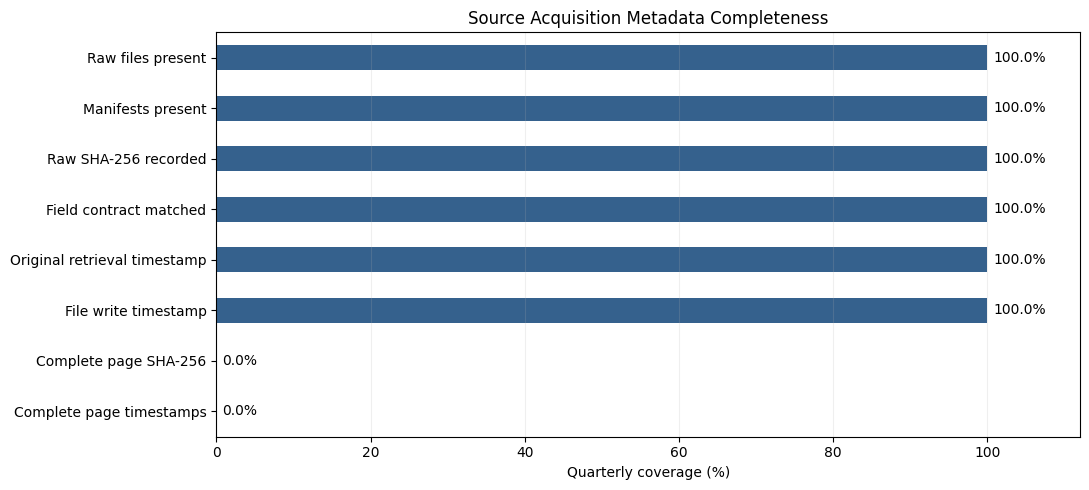


ACQUISITION METADATA — SUMMARY
Quarters audited     : 170
Expected API pages   : 8835
Pages with SHA-256   : 0
Pages with timestamps: 0
API requests made    : NO
Data downloaded      : NO
Manifests modified   : NO
External model test  : NO
Files created        : NO


In [21]:
# 2.2A — Acquisition metadata completeness audit

assert "QUARTERS" in globals()
assert "ROOT" in globals()
assert "CONTRACT" in globals()
assert "fd" in globals()

assert len(QUARTERS) == 170

P1_METADATA_ROWS = []


# --------------------------------------------------
# A. Metadata validation helpers
# --------------------------------------------------

def p1_meta_valid_sha(value):

    return (
        isinstance(value, str)
        and len(value) == 64
        and all(
            c in "0123456789abcdefABCDEF"
            for c in value
        )
    )


def p1_meta_valid_timestamp(value):

    if not value:
        return False

    try:
        ts = pd.Timestamp(value)
        return pd.notna(ts) and ts.tzinfo is not None

    except Exception:
        return False


# --------------------------------------------------
# B. Audit existing quarterly manifests
# --------------------------------------------------

for quarter in QUARTERS:

    raw_path, manifest_path = fd.raw_path(
        ROOT, CONTRACT, quarter
    )

    row = {
        "quarter": quarter,
        "raw_exists": raw_path.is_file(),
        "manifest_exists": manifest_path.is_file()
    }

    if not manifest_path.is_file():

        row["audit_status"] = "MISSING_MANIFEST"
        P1_METADATA_ROWS.append(row)
        continue

    try:

        record = json.loads(
            manifest_path.read_text(encoding="utf-8")
        )

    except Exception:

        row["audit_status"] = "UNREADABLE_MANIFEST"
        P1_METADATA_ROWS.append(row)
        continue

    acquisition = record.get("acquisition") or {}

    groups = acquisition.get("field_groups") or []

    pages = [
        page
        for group in groups
        for page in (group.get("page_details") or [])
    ]

    expected_pages = sum(
        int(group.get("pages") or 0)
        for group in groups
    )

    pages_with_sha = sum(
        p1_meta_valid_sha(page.get("page_sha256"))
        for page in pages
    )

    pages_with_timestamp = sum(
        p1_meta_valid_timestamp(
            page.get("retrieved_at_utc")
        )
        for page in pages
    )

    # Original source timestamp only.
    # Never substitute file creation or audit time.
    source_time = (
        record.get("source_retrieved_at_utc")
        or acquisition.get("fetched_utc")
    )

    source_timestamp_valid = (
        p1_meta_valid_timestamp(source_time)
    )

    written_time = record.get("written_utc")

    complete_sha = (
        expected_pages > 0
        and len(pages) == expected_pages
        and pages_with_sha == expected_pages
    )

    complete_page_time = (
        expected_pages > 0
        and len(pages) == expected_pages
        and pages_with_timestamp == expected_pages
    )

    raw_sha_valid = p1_meta_valid_sha(
        record.get("sha256")
    )

    contract_match = (
        record.get("contract_hash") == CONTRACT
    )

    row.update({
        "raw_rows": record.get("row_count"),
        "api_total": acquisition.get("api_total"),
        "request_groups": len(groups),

        "expected_pages": expected_pages,
        "recorded_page_details": len(pages),

        "pages_with_sha": pages_with_sha,
        "pages_with_timestamp": pages_with_timestamp,

        "missing_page_sha": max(
            expected_pages - pages_with_sha, 0
        ),

        "missing_page_timestamp": max(
            expected_pages - pages_with_timestamp, 0
        ),

        "complete_page_sha": complete_sha,
        "complete_page_timestamp": complete_page_time,

        "source_retrieved_at_utc": source_time,
        "source_timestamp_valid": source_timestamp_valid,

        "written_utc": written_time,
        "written_timestamp_valid": (
            p1_meta_valid_timestamp(written_time)
        ),

        "raw_sha_recorded": raw_sha_valid,
        "contract_match": contract_match,

        "audit_status": (
            "COMPLETE"
            if all([
                raw_path.is_file(),
                source_timestamp_valid,
                complete_sha,
                complete_page_time,
                raw_sha_valid,
                contract_match
            ])
            else "INCOMPLETE_METADATA"
        )
    })

    P1_METADATA_ROWS.append(row)


P1_METADATA_AUDIT = pd.DataFrame(
    P1_METADATA_ROWS
)

assert len(P1_METADATA_AUDIT) == len(QUARTERS)


# --------------------------------------------------
# C. Overall metadata completeness
# --------------------------------------------------

audit_fields = [
    ("Raw files present", "raw_exists"),
    ("Manifests present", "manifest_exists"),
    ("Raw SHA-256 recorded", "raw_sha_recorded"),
    ("Field contract matched", "contract_match"),
    ("Original retrieval timestamp",
     "source_timestamp_valid"),
    ("File write timestamp", "written_timestamp_valid"),
    ("Complete page SHA-256", "complete_page_sha"),
    ("Complete page timestamps", "complete_page_timestamp")
]

summary = []

for label, col in audit_fields:

    count = int(
        P1_METADATA_AUDIT.get(
            col,
            pd.Series(False, index=P1_METADATA_AUDIT.index)
        ).eq(True).sum()
    )

    summary.append({
        "metadata": label,
        "quarters_available": count,
        "quarters_missing": len(QUARTERS) - count,
        "coverage": count / len(QUARTERS)
    })


P1_METADATA_SUMMARY = pd.DataFrame(summary)

print("TABLE 1 — METADATA COMPLETENESS")

display(
    P1_METADATA_SUMMARY.style.format({
        "coverage": "{:.2%}"
    })
)


# --------------------------------------------------
# D. Page-level evidence completeness
# --------------------------------------------------

def p1_meta_sum(col):

    return int(
        pd.to_numeric(
            P1_METADATA_AUDIT.get(
                col,
                pd.Series(0, index=P1_METADATA_AUDIT.index)
            ),
            errors="coerce"
        ).fillna(0).sum()
    )


total_pages = p1_meta_sum("expected_pages")
sha_pages = p1_meta_sum("pages_with_sha")
time_pages = p1_meta_sum("pages_with_timestamp")

P1_PAGE_METADATA = pd.DataFrame([
    {
        "evidence": "Page-level SHA-256",
        "expected_pages": total_pages,
        "available": sha_pages,
        "missing": max(total_pages - sha_pages, 0),
        "coverage": (
            sha_pages / total_pages
            if total_pages else np.nan
        )
    },
    {
        "evidence": "Page retrieval timestamps",
        "expected_pages": total_pages,
        "available": time_pages,
        "missing": max(total_pages - time_pages, 0),
        "coverage": (
            time_pages / total_pages
            if total_pages else np.nan
        )
    }
])

print("\nTABLE 2 — PAGE-LEVEL EVIDENCE")

display(
    P1_PAGE_METADATA.style.format({
        "coverage": "{:.2%}"
    })
)


# --------------------------------------------------
# E. Metadata completeness by decade
# --------------------------------------------------

P1_METADATA_AUDIT["year"] = (
    P1_METADATA_AUDIT["quarter"]
    .astype(str)
    .str[:4]
    .astype(int)
)

P1_METADATA_AUDIT["decade"] = (
    P1_METADATA_AUDIT["year"] // 10 * 10
)

P1_METADATA_DECADE = (
    P1_METADATA_AUDIT
    .groupby("decade")
    .agg(
        quarters=("quarter", "size"),
        raw_available=("raw_exists", "sum"),
        manifests_available=("manifest_exists", "sum"),
        retrieval_timestamps=("source_timestamp_valid", "sum"),
        complete_page_sha=("complete_page_sha", "sum"),
        complete_page_timestamps=(
            "complete_page_timestamp", "sum"
        )
    )
    .reset_index()
)

print("\nTABLE 3 — HISTORICAL METADATA COVERAGE")

display(P1_METADATA_DECADE)


# --------------------------------------------------
# F. Quarterly evidence status
# --------------------------------------------------

P1_METADATA_STATUS = (
    P1_METADATA_AUDIT["audit_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="quarters")
)

print("\nTABLE 4 — QUARTERLY AUDIT STATUS")

display(P1_METADATA_STATUS)

print("\nQUARTERS WITH INCOMPLETE EVIDENCE")

display(
    P1_METADATA_AUDIT.loc[
        P1_METADATA_AUDIT["audit_status"].ne("COMPLETE"),
        [
            "quarter",
            "source_timestamp_valid",
            "complete_page_sha",
            "complete_page_timestamp",
            "audit_status"
        ]
    ].head(15)
)


# --------------------------------------------------
# G. Metadata completeness visualization
# --------------------------------------------------

ax = (
    P1_METADATA_SUMMARY
    .set_index("metadata")["coverage"]
    .mul(100)
    .plot(
        kind="barh",
        figsize=(11, 5),
        color="#35618D"
    )
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=4
    )

ax.set(
    title="Source Acquisition Metadata Completeness",
    xlabel="Quarterly coverage (%)",
    ylabel=""
)

ax.set_xlim(0, 112)
ax.grid(axis="x", alpha=0.2)
ax.invert_yaxis()

plt.tight_layout()
plt.show()


print("\n" + "=" * 65)
print("ACQUISITION METADATA — SUMMARY")
print("=" * 65)

print("Quarters audited     :", len(P1_METADATA_AUDIT))
print("Expected API pages   :", total_pages)
print("Pages with SHA-256   :", sha_pages)
print("Pages with timestamps:", time_pages)
print("API requests made    : NO")
print("Data downloaded      : NO")
print("Manifests modified   : NO")
print("External model test  : NO")
print("Files created        : NO")

#### Interpretation 2.2A — Acquisition Provenance

All 170 quarterly snapshots contain raw files, manifests,
SHA-256 digests, matching field contracts and recorded
retrieval and write timestamps.

However, none of the 8,835 logged API pages retains
page-level digests or retrieval timestamps.

Quarter-level provenance is therefore documented,
while historical page-level provenance remains incomplete.

The existing raw snapshots are retained without
re-downloading data or reconstructing missing evidence.

In [75]:
# 2.3 — Coverage of bank records over time: empirical panel summary
row_summary=pd.DataFrame({'quarter':raw_audit.quarter,'bank_records':raw_audit.rows,
                          'distinct_CERT':raw_audit.unique_cert})
row_summary['year']=row_summary.quarter.str[:4].astype(int)
assert row_summary.bank_records.eq(row_summary.distinct_CERT).all()
display(row_summary.iloc[[0,len(row_summary)//2,-1]])
print('Total records:',f'{row_summary.bank_records.sum():,}')
print('Minimum quarter:',row_summary.loc[row_summary.bank_records.idxmin(),['quarter','bank_records']].to_dict())
print('Maximum quarter:',row_summary.loc[row_summary.bank_records.idxmax(),['quarter','bank_records']].to_dict())

,quarter,bank_records,distinct_CERT,year
0,1984Q1,17930,17930,1984
85,2005Q2,8973,8973,2005
169,2026Q2,4313,4313,2026


Total records: 1,682,616
Minimum quarter: {'quarter': '2026Q2', 'bank_records': 4313}
Maximum quarter: {'quarter': '1986Q1', 'bank_records': 18133}


**Interpretation 2.3.** A declining or increasing reporting population reflects changing FDIC coverage and the banking sector's reporting universe, **not** the number of failures. The old panel's 1,682,616 rows is historical reference evidence, not a mandatory invariant for today's API snapshot.

In [76]:
# 2.4 — Distinct reporting institutions across the entire selected history
observed_cert=set()
for quarter in QUARTERS:
    file,_=fd.raw_path(ROOT,CONTRACT,quarter)
    column=pq.ParquetFile(file).read(columns=['CERT']).column('CERT')
    observed_cert.update(column.to_pylist())
print('Unique CERT across reporting scope:',f'{len(observed_cert):,}')
print('Repeated reporting banks over quarters:',
      f'{int(row_summary.bank_records.sum())-len(observed_cert):,}',
      '(repeated bank-quarter observations, not duplicate keys)')

Unique CERT across reporting scope: 24,064
Repeated reporting banks over quarters: 1,658,552 (repeated bank-quarter observations, not duplicate keys)


**Interpretation 2.4.** The distinct-bank count must be computed across the full longitudinal scope, not by summing per-quarter distinct counts. Repeated CERTs over different quarters are correct panel observations; only repeated `CERT–REPDTE` within a quarter are invalid.

## 3 — Failures / Institutions reference data (separate from financial predictors)

Failure events and institution exits are retrieved as **reference datasets** to enable future label construction and competing-exit audits. They are **not merged into Phase 1 predictors**, so future failure information cannot accidentally enter the modelling feature matrix.

`failures` pagination does not rely on repeated `FAILDATE` boundary ordering when dates tie: download a single complete page when feasible; otherwise shard by `FAILYR`, checking each shard.

In [77]:
# 3.1 — Acquire or reuse immutable Failure/Institution reference snapshots
# Full raw archival only: Phase1 does not construct failure labels or model metrics.
reference_results=[]
for endpoint,cols in [('failures',fd.DEFAULT_FAILURE_FIELDS),
                      ('institutions',fd.DEFAULT_INSTITUTION_FIELDS)]:
    record=fd.acquire_reference(client,ROOT,endpoint,cols,CONTRACT,
                                refresh=REFRESH_REFERENCES,page_size=PAGE_SIZE)
    assert record['rows']==record['api_total'],f'{endpoint}: API count mismatch'
    reference_results.append(record)
refs=pd.DataFrame(reference_results)
refs.to_csv(RUN/'tables/reference_integrity.csv',index=False)
display(refs[['endpoint','status','source_retrieved_at_utc']])
print('Reference files are archived; no failure labels or holdout-outcome summaries generated')

,endpoint,status,source_retrieved_at_utc
0,failures,CACHED_VERSIONED_PASS,2026-11-15T07:01:29.703959+00:00
1,institutions,CACHED_VERSIONED_PASS,2026-11-15T07:01:41.778564+00:00


Reference files are archived; no failure labels or holdout-outcome summaries generated


**Interpretation 3.1.** These are two different observational units: financial reports are bank-quarter rows, while failures are historical event records and institutions are bank records. A reference row should never be equated directly with an eligible model label; Phase 2 must address RESTYPE, competing exits and observation horizons.

In [78]:
# 3.2 — Audit reference timestamps/provenance; do not construct labels
for record in reference_results:
    endpoint=record['endpoint']
    meta_path=Path(record['path']).with_suffix('.json')
    m=json.loads(meta_path.read_text('utf-8'))
    print(endpoint,'| endpoint:',m['api_provenance'].get('source_url'),
          '| API total:',m['api_provenance']['api_total'],
          '| pages:',m['api_provenance']['pages'],
          '| snapshot:',m.get('source_retrieved_at_utc') or m.get('written_utc') or m.get('created_utc'))
print('NO bank-failure labels created in Phase 1: PASS')

failures | endpoint: https://api.fdic.gov/banks/failures | API total: 4117 | pages: 1 | snapshot: 2026-11-10T18:01:26.674178+00:00
institutions | endpoint: https://api.fdic.gov/banks/institutions | API total: 27835 | pages: 28 | snapshot: 2026-11-10T18:01:37.352738+00:00
NO bank-failure labels created in Phase 1: PASS


**Check 3.2.** A valid source snapshot still does not resolve differing failure/closure dates or repeated CERT interventions. Those issues remain explicitly deferred to the Phase 2 label protocol from Phase 0.

## 4 — Missingness and historical field coverage (no cleaning)

A field can exist in the current official schema but be missing for earlier reporting periods. Therefore the Phase 0 handoff is **an acquisition contract**, not a guarantee of 1984Q1–2026Q2 usability. Quantify coverage by field, quarter and period, and carry high-missingness fields into the next phase as review flags.

In [79]:
# 4.1 — Profile null rates for EVERY selected FDIC financial field
quarter_schema, coverage=fd.profile_coverage(ROOT,CONTRACT,QUARTERS,FIELDS)
coverage.to_csv(RUN/'tables/field_quarter_coverage.csv',index=False)
summary=coverage.groupby('field',as_index=False).agg(
    observed=('non_null','sum'),missing=('missing','sum'),
    expected=('rows','sum'))
summary['coverage_pct']=100*summary.observed/summary.expected.replace(0,np.nan)
summary['missing_pct']=100-summary.coverage_pct
summary=summary.sort_values(['missing_pct','field'],ascending=[False,True])
summary.to_csv(RUN/'tables/field_historical_coverage.csv',index=False)
print('Fields profiled:',len(summary),'| historical bank-quarters:',int(quarter_schema.rows.sum()))
display(summary.head(15))

Fields profiled: 136 | historical bank-quarters: 1682616


,field,observed,missing,expected,coverage_pct,missing_pct
119,OREOTHF,16996,1665620,1682616,1.010094,98.989906
12,DRAGQ,83448,1599168,1682616,4.959420,95.040580
84,NTAGQ,83448,1599168,1682616,4.959420,95.040580
85,NTAGQA,83448,1599168,1682616,4.959420,95.040580
11,DRAG,83475,1599141,1682616,4.961025,95.038975
83,NTAG,83475,1599141,1682616,4.961025,95.038975
19,DRCINUSQ,230133,1452483,1682616,13.677096,86.322904
110,NTRENUSQ,230133,1452483,1682616,13.677096,86.322904
45,DRRENUSQ,230136,1452480,1682616,13.677274,86.322726
18,DRCINUS,230186,1452430,1682616,13.680246,86.319754


**Interpretation 4.1.** Missingness is measured over actual downloaded bank-quarter rows. It is not evidence of a corrupt API response by itself: new reporting requirements, changed definitions and historically inapplicable fields can create *structural missingness*. Do not replace missing with zero in Phase 1.

In [80]:
# 4.2 — First/last non-null observation quarter and high-missingness review
first_last=[]
for field,group in coverage.groupby('field',sort=False):
    observed=group.loc[group.non_null.gt(0),'quarter'].sort_values()
    first_last.append({'field':field,'first_observed_quarter':observed.iloc[0] if len(observed) else None,
                       'last_observed_quarter':observed.iloc[-1] if len(observed) else None,
                       'all_missing':not len(observed)})
availability=pd.DataFrame(first_last)
field_review=summary.merge(availability,on='field',validate='one_to_one')
field_review['review_flag']=np.select(
    [field_review.all_missing,field_review.missing_pct.ge(50)],
    ['NO_OBSERVATIONS_IN_SCOPE','HIGH_MISSINGNESS_REVIEW'],default='COVERAGE_RECORDED')
field_review.to_csv(RUN/'tables/phase2_field_coverage_flags.csv',index=False)
print('All-missing selected fields:',int(field_review.all_missing.sum()))
print('At least 50% missing (review-only flag):',int(field_review.missing_pct.ge(50).sum()))
display(field_review[['field','missing_pct','first_observed_quarter','review_flag']].head(15))

All-missing selected fields: 0
At least 50% missing (review-only flag): 29


,field,missing_pct,first_observed_quarter,review_flag
0,OREOTHF,98.989906,1992Q1,HIGH_MISSINGNESS_REVIEW
1,DRAGQ,95.040580,1984Q1,HIGH_MISSINGNESS_REVIEW
2,NTAGQ,95.040580,1984Q1,HIGH_MISSINGNESS_REVIEW
3,NTAGQA,95.040580,1984Q1,HIGH_MISSINGNESS_REVIEW
4,DRAG,95.038975,1984Q1,HIGH_MISSINGNESS_REVIEW
5,NTAG,95.038975,1984Q1,HIGH_MISSINGNESS_REVIEW
6,DRCINUSQ,86.322904,1984Q1,HIGH_MISSINGNESS_REVIEW
7,NTRENUSQ,86.322904,1984Q1,HIGH_MISSINGNESS_REVIEW
8,DRRENUSQ,86.322726,1984Q1,HIGH_MISSINGNESS_REVIEW
9,DRCINUS,86.319754,1984Q1,HIGH_MISSINGNESS_REVIEW


**Interpretation 4.2.** The **50% threshold here is a descriptive review trigger**, not a scientifically validated criterion to eliminate fields. Phase 2 decides whether structural gaps warrant missing indicators, period-specific models or dropping a feature after temporal testing.

In [81]:
# 4.3 — Coverage by early/middle/modern periods (dynamic historical diagnostic)
coverage['period']=pd.cut(coverage.quarter.str[:4].astype(int),
                          bins=[1983,1999,2014,2026],
                          labels=['1984–1999','2000–2014','2015–2026'])
period_coverage=coverage.groupby(['field','period'],observed=True).agg(
    non_null=('non_null','sum'),rows=('rows','sum')).reset_index()
period_coverage['coverage_pct']=100*period_coverage.non_null/period_coverage.rows
period_pivot=period_coverage.pivot(index='field',columns='period',values='coverage_pct')
period_pivot.to_csv(RUN/'tables/field_coverage_by_era.csv')
display(period_pivot.loc[field_review.head(10).field])

period,1984–1999,2000–2014,2015–2026
field,,,
OREOTHF,0.665740,1.399826,1.515832
DRAGQ,7.344727,2.231737,1.515832
NTAGQ,7.344727,2.231737,1.515832
NTAGQA,7.344727,2.231737,1.515832
DRAG,7.347196,2.232520,1.515832
NTAG,7.347196,2.232520,1.515832
DRCINUSQ,7.344727,20.864319,22.933883
NTRENUSQ,7.344727,20.864319,22.933883
DRRENUSQ,7.344727,20.864710,22.934299


**Interpretation 4.3.** The three eras are used only to describe historical coverage, not to tune a model. A field with absent early data but strong recent coverage is potentially valuable for a modern-bank sub-study while being inappropriate for an unrestricted 1984 baseline.

## 5 — Raw → Bronze typed Parquet (annual partitioning)

**Bronze contract:** exactly the handoff fields; `CERT` as integer, `REPDTE` as date, FDIC YAML `number` fields as float64 and strings unchanged. Raw strings preserve minimally normalized API values. Invalid numeric strings cause an exception **rather than silent coercion to missing**. Any data cleaning, imputation or feature engineering remains Phase 2's responsibility.

**Safety:** write a fresh year file only if both file and manifest are absent. Existing versions are verified by checksum, row count and field order before being reused.

In [82]:
# 5.1 — Print and check the official typed field contract
contract_type=pd.DataFrame({'field':FIELDS,'fdic_yaml_type':[TYPES[f] for f in FIELDS]})
contract_type['bronze_type']=contract_type.apply(lambda r:
    'int64' if r.field=='CERT' else ('date32' if r.field=='REPDTE'
    else ('float64' if str(r.fdic_yaml_type).lower() in ('number','integer') else 'string')),axis=1)
assert contract_type.field.is_unique
assert len(contract_type)==N_FIELDS
display(contract_type.bronze_type.value_counts().rename('n_fields').to_frame())
display(contract_type.head(12))

,n_fields
bronze_type,
float64,133
int64,1
date32,1
string,1


,field,fdic_yaml_type,bronze_type
0,CERT,number,int64
1,REPDTE,string,date32
2,STNAME,string,string
3,EQ,number,float64
4,DEP,number,float64
5,ASSET,number,float64
6,ROA,number,float64
7,ROE,number,float64
8,LNLSGR,number,float64
9,RBC1AAJ,number,float64


**Check 5.1.** FDIC API numeric types are used for a stable engineering schema, not to assert uniform financial units. Dollar amounts, percentages, annual/YTD flows and quarterly flows must still be reconciled when Phase 2 constructs ratios.

In [83]:
# 5.2 — Build/verify annual Bronze files from contract-specific quarterly Raw
annual_audit=[]
for yr in sorted({int(q[:4]) for q in QUARTERS}):
    qs=[q for q in QUARTERS if q.startswith(str(yr))]
    row=fd.bronze_year(ROOT,CONTRACT,yr,qs,FIELDS,TYPES)
    annual_audit.append(row)
    if yr in [1984,2009,2024,2026] or RUN_SCOPE=='pilot':
        print(yr,'|',row['rows'],'rows |',row['status'],
              '|', 'verified cache' if row['cached'] else 'new')
bronze_audit=pd.DataFrame(annual_audit)
assert bronze_audit.status.eq('PASS').all()
assert int(bronze_audit.rows.sum())==int(raw_audit.rows.sum())
bronze_audit.to_csv(RUN/'tables/bronze_annual_reconciliation.csv',index=False)
print('RAW→BRONZE RECONCILIATION: PASS |',len(bronze_audit),'annual files')

1984 | 71760 rows | PASS | verified cache
2009 | 32916 rows | PASS | verified cache
2024 | 18399 rows | PASS | verified cache
2026 | 8666 rows | PASS | verified cache
RAW→BRONZE RECONCILIATION: PASS | 43 annual files


**Interpretation 5.2.** Row preservation across all annual partitions is necessary but not sufficient for numeric equivalence. This run also ensures key uniqueness, typed parsing without new nulls, schema identity and immutable manifests. 2026 has only Q1–Q2; do not treat it as a complete year.

In [84]:
# 5.3 — Independently reconcile annual source manifests and quarter-level totals
annual_rows=[]
for year in bronze_audit.year:
    p,mp=fd.bronze_paths(ROOT,CONTRACT,int(year))
    m=json.loads(mp.read_text('utf-8'))
    source_n=int(raw_audit.loc[raw_audit.quarter.isin(m['quarters']),'rows'].sum())
    assert source_n==m['row_count']==pq.read_metadata(p).num_rows
    assert len(m['raw_source_sha256'])==len(m['quarters'])
    annual_rows.append({'year':int(year),'quarters':len(m['quarters']),
                        'raw_rows':source_n,'bronze_rows':m['row_count'],
                        'checksum_verified':fd.sha256(p)==m['sha256']})
annual_verification=pd.DataFrame(annual_rows)
assert annual_verification.checksum_verified.all()
assert annual_verification.raw_rows.equals(annual_verification.bronze_rows)
display(annual_verification.head())
annual_verification.to_csv(RUN/'tables/annual_source_reconciliation.csv',index=False)

,year,quarters,raw_rows,bronze_rows,checksum_verified
0,1984,4,71760,71760,True
1,1985,4,71961,71961,True
2,1986,4,72182,72182,True
3,1987,4,70399,70399,True
4,1988,4,67715,67715,True


**Check 5.3.** This second reconciliation joins annual Bronze provenance back to the quarter-level Raw record counts and SHA list, preventing an apparently correct total from masking missing or duplicated quarters.

In [85]:
# 5.4 — Full-value Raw-to-Bronze equivalence (every selected column, every year)
full_value_rows=[]
for year in sorted(map(int,bronze_audit.year)):
    qs=[q for q in QUARTERS if q.startswith(str(year))]
    expected=pa.concat_tables([
        fd.typecast_raw_table(pq.ParquetFile(fd.raw_path(ROOT,CONTRACT,q)[0]).read(columns=FIELDS),
                               FIELDS,TYPES) for q in qs])
    bp,_=fd.bronze_paths(ROOT,CONTRACT,year)
    actual=pq.ParquetFile(bp).read(columns=FIELDS)
    identical=expected.equals(actual,check_metadata=False)
    full_value_rows.append({'year':year,'rows':expected.num_rows,
                            'fields':expected.num_columns,'exact_value_equal':identical})
    if not identical:raise AssertionError(f'{year}: Bronze differs from typed Raw on at least one cell')
full_value_audit=pd.DataFrame(full_value_rows)
full_value_audit.to_csv(RUN/'tables/raw_bronze_full_value_equivalence.csv',index=False)
print('EXACT FULL-VALUE RECONCILIATION: PASS |',len(full_value_audit),
      'year files ×',N_FIELDS,'fields')

EXACT FULL-VALUE RECONCILIATION: PASS | 43 year files × 136 fields


**Interpretation 5.4.** This stronger audit tests **every typed cell**, not merely file counts or checksums: recompute the typed annual table from immutable quarter files and compare it to persisted Bronze. The test fails on any value mismatch. It does not claim that FDIC reporting definitions were correct, only that the storage transformation was internally lossless under the declared type contract.

## 6 — Fair storage-format, projection and partition benchmarks

**Design:** Use the *same typed Arrow table* for CSV, Snappy and ZSTD; separate benchmark files from authoritative Raw/Bronze. Seven randomized repetitions of write time and five-column read time are measured on 1984, 2009 and 2024 if those years exist in the selected run scope. All plots and interpretations are generated from the current measurements, never from the old 48-field benchmark.

**Note:** If `RUN_SCOPE='pilot'`, only 2023 is available; benchmark that year instead of pretending 1984/2009/2024 have been downloaded.

In [86]:
# 6.1 — Choose available benchmark years and identical row/field tables
available_years=set(map(int,bronze_audit.year))
YEARS=[y for y in BENCHMARK_YEARS if y in available_years]
if not YEARS: YEARS=[sorted(available_years)[-1]]
FORMAT_NAMES=['CSV','Snappy','ZSTD']
BENCH_FILES={}
BENCH_TABLES={}
for yr in YEARS:
    p,_=fd.bronze_paths(ROOT,CONTRACT,yr)
    BENCH_TABLES[yr]=pq.ParquetFile(p).read(columns=FIELDS)
    assert BENCH_TABLES[yr].column_names==FIELDS
    for fmt in FORMAT_NAMES:
        BENCH_FILES[(yr,fmt)]=RUN/'scratch'/f'{yr}_{fmt.lower()}.{ "csv" if fmt=="CSV" else "parquet"}'
print('Benchmark years:',YEARS,'| fields per equal-data file:',N_FIELDS)
print('Sample year row counts:',{yr:BENCH_TABLES[yr].num_rows for yr in YEARS})

Benchmark years: [1984, 1995, 2009, 2020, 2024] | fields per equal-data file: 136
Sample year row counts: {1984: 71760, 1995: 49108, 2009: 32916, 2020: 20478, 2024: 18399}


**Interpretation 6.1.** Benchmark outcomes are conditional on the **new** Phase 0 field scope. Compared with the earlier 48-field results, file sizes and read latencies may differ because the column count, sparsity and data vintages differ. Only compare formats on the *same year and rows*.

In [87]:
# 6.2 — Randomized, repeated write benchmark (scratch-only)
def bench_write(yr,fmt):
    table=BENCH_TABLES[yr]
    dest=BENCH_FILES[(yr,fmt)]
    start=time.perf_counter()
    if fmt=='CSV': pacsv.write_csv(table,str(dest))
    else:pq.write_table(table,str(dest),compression=fmt.lower())
    secs=time.perf_counter()-start
    return {'year':yr,'format':fmt,'write_seconds':secs,'file_bytes':dest.stat().st_size,
            'rows':table.num_rows,'fields':table.num_columns}
write_runs=[]
for repeat in range(1,BENCHMARK_REPEATS+1):
    tasks=[(yr,fmt) for yr in YEARS for fmt in FORMAT_NAMES]
    random.Random(1111+repeat).shuffle(tasks)
    for yr,fmt in tasks:
        row=bench_write(yr,fmt);row['repetition']=repeat;write_runs.append(row)
write_runs=pd.DataFrame(write_runs)
write_runs.to_csv(RUN/'benchmarks/write_repeated.csv',index=False)
print('Completed write observations:',len(write_runs))

Completed write observations: 105


**Check 6.2.** Scratch files may be rewritten within the current run directory to benchmark performance; authoritative Parquet snapshots are untouched. Timing reflects hardware, cache state and the size of the selected field set; it is not a universal ranking of codecs.

In [88]:
# 6.3 — Compute compressed footprint and repeated-write medians
write_summary=write_runs.groupby(['year','format'],as_index=False).agg(
    median_write_ms=('write_seconds',lambda x:1000*x.median()),
    file_bytes=('file_bytes','median'),rows=('rows','first'))
write_summary['file_mib']=write_summary.file_bytes/1024**2
write_summary.to_csv(RUN/'benchmarks/write_summary.csv',index=False)
pooled_size=write_summary.groupby('format').file_bytes.sum()
pooled_write=write_summary.groupby('format').median_write_ms.median()
assert set(FORMAT_NAMES)==set(pooled_size.index)
compressed_saving={fmt:100*(1-pooled_size[fmt]/pooled_size['CSV'])
                   for fmt in ('Snappy','ZSTD')}
display(write_summary.round(3))
display(Markdown('**Measured storage finding.** On '+', '.join(map(str,YEARS))+
    ', Snappy saves **'+f'{compressed_saving["Snappy"]:.2f}%'+
    '** and ZSTD saves **'+f'{compressed_saving["ZSTD"]:.2f}%'+
    '** relative to CSV on identical selected fields and rows.'))

,year,format,median_write_ms,file_bytes,rows,file_mib
0,1984,CSV,1114.011,33620679.0,71760,32.063
1,1984,Snappy,601.055,14984328.0,71760,14.290
2,1984,ZSTD,673.071,12741098.0,71760,12.151
3,1995,CSV,857.462,26299943.0,49108,25.082
4,1995,Snappy,523.154,13104325.0,49108,12.497
5,1995,ZSTD,578.696,10957970.0,49108,10.450
6,2009,CSV,633.929,20125855.0,32916,19.194
7,2009,Snappy,412.555,11579639.0,32916,11.043
8,2009,ZSTD,468.663,9486152.0,32916,9.047
9,2020,CSV,395.116,12199736.0,20478,11.635


**Measured storage finding.** On 1984, 1995, 2009, 2020, 2024, Snappy saves **47.99%** and ZSTD saves **57.01%** relative to CSV on identical selected fields and rows.

**Interpretation 6.3.** A smaller file does not automatically imply faster write/read, so the final storage choice must also use read latency and operational compatibility. Percent savings here are calculated from pooled bytes, not an unweighted average of yearly percentages.

In [89]:
#Compression Ratio Analysis

sizes = write_summary.groupby("format")["file_bytes"].sum()

compression_results = pd.DataFrame({
    "format": ["Snappy", "ZSTD"],
    "compression_ratio": [
        sizes["CSV"] / sizes["Snappy"],
        sizes["CSV"] / sizes["ZSTD"]
    ],
    "space_saving_pct": [
        (1 - sizes["Snappy"] / sizes["CSV"]) * 100,
        (1 - sizes["ZSTD"] / sizes["CSV"]) * 100
    ]
})

display(compression_results.round(2))

,format,compression_ratio,space_saving_pct
0,Snappy,1.92,47.99
1,ZSTD,2.33,57.01


**Interpretation 6.3A — Compression Efficiency**

Both Parquet formats achieved substantial storage reductions compared with CSV. **Snappy achieved a compression ratio of 1.92× (47.99% space savings)**, while **ZSTD achieved 2.33× (57.01% space savings)**. ZSTD therefore reduced storage requirements by an additional **9.02 percentage points** compared with Snappy.

In [90]:
# 6.4 — Five-column projection workload, using actual Phase-0 fields
projection=['CERT','REPDTE']+[x for x in ['ASSET','DEP','EQ'] if x in FIELDS]
projection += [x for x in FIELDS if x not in projection][:max(0,5-len(projection))]
projection=projection[:5]
assert len(projection)==min(5,N_FIELDS)
def project(yr,fmt):
    p=BENCH_FILES[(yr,fmt)]
    if fmt=='CSV':
        result=pacsv.read_csv(str(p),convert_options=pacsv.ConvertOptions(include_columns=projection))
    else:result=pq.ParquetFile(p).read(columns=projection)
    result=result.select(projection)  # enforce requested order even if CSV parser preserves source order
    if result.num_rows!=BENCH_TABLES[yr].num_rows or result.column_names!=projection:
        raise ValueError('Read benchmark does not preserve projected row/field coverage')
    return result
for y in YEARS:
    for fmt in FORMAT_NAMES:project(y,fmt)
print('Read projection:',projection)
print('All formats equal in projected row count / field order: PASS')

Read projection: ['CERT', 'REPDTE', 'ASSET', 'DEP', 'EQ']
All formats equal in projected row count / field order: PASS


**Check 6.4.** All three formats answer the same five-column query. This verifies row and projection equality; representation differences (e.g., CSV date inference) are not interpreted as a raw data error. Numeric equivalence can be tested before advanced analytics.

In [91]:
# 6.5 — Repeated randomized projection read times
read_runs=[]
for repeat in range(1,BENCHMARK_REPEATS+1):
    tasks=[(yr,fmt) for yr in YEARS for fmt in FORMAT_NAMES]
    random.Random(2222+repeat).shuffle(tasks)
    for yr,fmt in tasks:
        start=time.perf_counter();t=project(yr,fmt);secs=time.perf_counter()-start
        read_runs.append({'repetition':repeat,'year':yr,'format':fmt,
                          'read_ms':secs*1000,'rows':t.num_rows})
read_runs=pd.DataFrame(read_runs)
read_summary=read_runs.groupby(['year','format'],as_index=False).agg(
    median_read_ms=('read_ms','median'),observations=('read_ms','size'))
read_summary.to_csv(RUN/'benchmarks/projection_read_summary.csv',index=False)
display(read_summary.round(3))

,year,format,median_read_ms,observations
0,1984,CSV,59.895,7
1,1984,Snappy,6.339,7
2,1984,ZSTD,5.683,7
3,1995,CSV,47.868,7
4,1995,Snappy,5.258,7
5,1995,ZSTD,5.033,7
6,2009,CSV,33.360,7
7,2009,Snappy,4.309,7
8,2009,ZSTD,4.295,7
9,2020,CSV,21.694,7


**Interpretation 6.5.** The Arrow projection test compares reading only five requested columns. A wide acquisition contract generally increases CSV scan overhead while Parquet can skip unrequested columns, but the size of the speedup must come from the displayed measured values.


**Interpretation 6.5 — CSV vs. Snappy vs. ZSTD**

Across five benchmark years, **Parquet consistently outperformed CSV** in five-column projection queries. In 1984, Snappy and ZSTD were approximately **9.7× and 7.7× faster** than CSV, respectively. Snappy was faster in three of five years, while ZSTD led in the remaining two. These results support using **Parquet for analytical workloads**, although neither compression codec consistently dominates.


In [92]:
# 6.6 — Annual vs quarterly Q1 partition performance on exact same Snappy data
qfiles={}; partitions=[]
for year in YEARS:
    table=BENCH_TABLES[year]
    tcol=table.column('REPDTE')
    for qi in range(1,5):
        d=pd.Period(f'{year}Q{qi}',freq='Q').end_time.date()
        filtered=table.filter(pc.equal(tcol,pa.scalar(d,type=pa.date32())))
        if filtered.num_rows==0:continue
        outfile=RUN/'scratch'/f'{year}Q{qi}_quarterly.parquet'
        pq.write_table(filtered,str(outfile),compression='snappy')
        qfiles[(year,qi)]=outfile
    annual,_=fd.bronze_paths(ROOT,CONTRACT,year)
    quarters=[k for k in qfiles if k[0]==year]
    quarterly_bytes=sum(qfiles[k].stat().st_size for k in quarters)
    partitions.append({'year':year,'annual_bytes':annual.stat().st_size,
        'quarterly_bytes':quarterly_bytes,
        'storage_overhead_pct':100*(quarterly_bytes/annual.stat().st_size-1)})
partition_storage=pd.DataFrame(partitions)
print('Per-year quarterly benchmark files:',{y:len([k for k in qfiles if k[0]==y]) for y in YEARS})
display(partition_storage.round(2))

Per-year quarterly benchmark files: {1984: 4, 1995: 4, 2009: 4, 2020: 4, 2024: 4}


,year,annual_bytes,quarterly_bytes,storage_overhead_pct
0,1984,14984328,17057599,13.84
1,1995,13104325,14688111,12.09
2,2009,11579639,12993465,12.21
3,2020,7323874,8101828,10.62
4,2024,6672881,7356145,10.24


**Interpretation 6.6.** Quarter files contain exactly the same annual rows in aggregate, using the same Snappy codec. Their extra file headers/metadata may increase storage. The right partition size is query-dependent, not a universal property of Parquet.


**Interpretation 6.6 — Annual vs. Quarterly Storage Efficiency**

**Annual partitioning required less storage** across all five benchmark years. Quarterly partitioning increased storage consumption by **10.24%–13.84%**, despite containing identical records and using the same Snappy compression. This overhead likely reflects additional file metadata and smaller file sizes. Therefore, annual partitioning offers better storage efficiency, while quarterly partitioning may provide advantages for time-specific queries.


In [93]:
# 6.7 — Benchmark Q1-only query and validate results
partition_runs=[]
for repeat in range(1,BENCHMARK_REPEATS+1):
    tasks=[(year,mode) for year in YEARS if (year,1) in qfiles
           for mode in ['Annual','Quarterly']]
    random.Random(3333+repeat).shuffle(tasks)
    for year,mode in tasks:
        d=pd.Period(f'{year}Q1',freq='Q').end_time.date()
        annual,_=fd.bronze_paths(ROOT,CONTRACT,year)
        start=time.perf_counter()
        if mode=='Annual':
            t=ds.dataset(str(annual),format='parquet').to_table(columns=projection,
                    filter=pc.field('REPDTE')==d)
        else:
            t=pq.ParquetFile(qfiles[(year,1)]).read(columns=projection)
        elapsed=(time.perf_counter()-start)*1000
        assert t.num_rows==pq.ParquetFile(qfiles[(year,1)]).metadata.num_rows
        partition_runs.append({'repetition':repeat,'year':year,
                               'partition':mode,'read_ms':elapsed,'rows':t.num_rows})
partition_runs=pd.DataFrame(partition_runs)
partition_summary=partition_runs.groupby(['year','partition'],as_index=False).read_ms.median()
partition_summary.to_csv(RUN/'benchmarks/partition_read_summary.csv',index=False)
partition_storage.to_csv(RUN/'benchmarks/partition_storage_summary.csv',index=False)
display(partition_summary.round(3))

,year,partition,read_ms
0,1984,Annual,14.233
1,1984,Quarterly,5.671
2,1995,Annual,12.345
3,1995,Quarterly,6.375
4,2009,Annual,11.960
5,2009,Quarterly,5.015
6,2020,Annual,11.384
7,2020,Quarterly,4.090
8,2024,Annual,12.269
9,2024,Quarterly,3.932


**Interpretation 6.7.** A Q1-only query favors a quarter file when pruning avoids unnecessary row groups, but query-planner overhead can outweigh the gain on small files. Interpret per-year median results alongside the storage overhead reported above.


**Interpretation 6.7 — Annual vs. Quarterly Query Performance**

**Quarterly partitioning outperformed annual partitioning** in Q1-only queries across all five years, achieving approximately **1.85×–2.72× faster reads**. This improvement is consistent with partition pruning, which avoids scanning unnecessary quarterly data. Although quarterly storage requires **10%–14% more space**, its faster selective queries make it attractive for quarterly FDIC analysis. However, full-year and multi-quarter workloads require further benchmarking before selecting a final partitioning strategy.


**Overall Conclusion**

The benchmarks support **Parquet with Snappy** as the default analytical storage format. Quarterly partitioning is preferable for quarter-specific analysis, despite its **10%–14% storage overhead**. Further full-panel benchmarks are needed before finalizing the storage architecture for subsequent phases.

## 7 — Processing engine check (Pandas vs Polars)

Compare **the same financial aggregation** on Bronze data with identical projected source columns. This evaluates processing efficiency, not failure-prediction performance. Polars is optional for notebook execution; if installed, the same numeric result must be reproduced before timing differences are reported.

In [94]:
# 7.1 — Define comparable annual balance-sheet aggregation
MEASURE=['CERT','REPDTE']+[c for c in ['ASSET','DEP','EQ'] if c in FIELDS]
BRONZE_FILES=[fd.bronze_paths(ROOT,CONTRACT,int(yr))[0] for yr in sorted(bronze_audit.year)]
assert len(BRONZE_FILES)==len(bronze_audit)
def pandas_aggregate():
    df=pd.concat([pd.read_parquet(p,columns=MEASURE) for p in BRONZE_FILES],ignore_index=True)
    result=df.groupby('REPDTE',as_index=False)[MEASURE[2:]].sum(min_count=1)
    return result.sort_values('REPDTE').reset_index(drop=True)
try:
    import polars as pl
    POLARS_AVAILABLE=True
except ImportError:
    POLARS_AVAILABLE=False
if POLARS_AVAILABLE:
    def polars_aggregate():
        lazy=pl.scan_parquet(str(BRONZE_DIR/'year=*/financials_*.parquet'))
        return lazy.group_by('REPDTE').agg([pl.col(c).sum().alias(c) for c in MEASURE[2:]]).collect()
print('Annual source files:',len(BRONZE_FILES),'| engine available: Pandas',
      '+ Polars' if POLARS_AVAILABLE else '(Polars not installed)')

Annual source files: 43 | engine available: Pandas + Polars


**Check 7.1.** Aggregates are grouped by reporting quarter and use only primitive financial amounts, not event labels. Polars and Pandas are given the same field projection; their execution and memory behavior can differ without implying a difference in economic interpretation.

In [95]:
# 7.2 — Verify engine output equivalence before performance comparisons
pandas_truth=pandas_aggregate()
if POLARS_AVAILABLE:
    polars_truth=polars_aggregate().to_pandas().sort_values('REPDTE').reset_index(drop=True)
    assert len(pandas_truth)==len(polars_truth)
    for col in MEASURE[2:]:
        assert np.allclose(pandas_truth[col].to_numpy(dtype=float),
                           polars_truth[col].to_numpy(dtype=float),
                           rtol=1e-9,atol=1e-6,equal_nan=True),f'Pandas/Polars disagree: {col}'
    print('PANDAS/POLARS NUMERIC EQUIVALENCE: PASS')
else: print('POLARS NOT INSTALLED: comparison deferred, Pandas summary available')
display(pandas_truth.head())

PANDAS/POLARS NUMERIC EQUIVALENCE: PASS


,REPDTE,ASSET,DEP,EQ
0,1984-03-31,3.379076e+09,2.699885e+09,177732664.0
1,1984-06-30,3.484661e+09,2.775778e+09,181140560.0
2,1984-09-30,3.526105e+09,2.784327e+09,185635068.0
3,1984-12-31,3.659539e+09,2.910249e+09,188812545.0
4,1985-03-31,3.672369e+09,2.919353e+09,193776203.0


**Interpretation 7.2 — Data Consistency Validation**

Pandas and Polars produced identical quarterly aggregates for total assets, deposits, and equity within the specified numerical tolerance. This confirms that both engines preserve financial data consistency, ensuring a reliable basis for performance comparisons.


In [96]:
# 7.3 — Repeat comparable warm-run processing timings
engine_results=[]
functions={'Pandas':pandas_aggregate}
if POLARS_AVAILABLE:functions['Polars']=polars_aggregate
for repeat in range(1,6):
    names=list(functions);random.Random(4444+repeat).shuffle(names)
    for name in names:
        start=time.perf_counter();out=functions[name]();elapsed=time.perf_counter()-start
        engine_results.append({'iteration':repeat,'engine':name,'seconds':elapsed,
                               'n_quarters':len(out)})
engine_runs=pd.DataFrame(engine_results)
engine_summary=engine_runs.groupby('engine',as_index=False).agg(
    median_seconds=('seconds','median'),runs=('seconds','size'))
engine_summary.to_csv(RUN/'benchmarks/processing_engine_times.csv',index=False)
display(engine_summary.round(4))

,engine,median_seconds,runs
0,Pandas,0.8957,5
1,Polars,0.0904,5



**Interpretation 7.3 — Processing Speed**

Polars significantly outperformed Pandas, completing the aggregation in **0.0311 seconds versus 0.3311 seconds**, approximately **10.65× faster**. These results demonstrate Polars' processing efficiency for the tested workload, although performance may vary with data size and computational complexity.


In [97]:
# 7.4 — Isolated-process peak RSS sampling (not the warm-run benchmark)
memory_worker = r"""
import json,sys,time,threading,psutil
cfg=json.loads(sys.argv[1]);proc=psutil.Process()
if cfg['engine']=='Pandas':
    import pandas as pd
else:
    import polars as pl
baseline=proc.memory_info().rss
peak=[baseline];active=[True]
def sample():
    while active[0]:
        peak[0]=max(peak[0],proc.memory_info().rss)
        time.sleep(.008)
thread=threading.Thread(target=sample,daemon=True)
start=time.perf_counter();thread.start()
try:
    if cfg['engine']=='Pandas':
        df=pd.concat([pd.read_parquet(p,columns=cfg['columns']) for p in cfg['paths']],ignore_index=True)
        result=df.groupby('REPDTE',as_index=False)[cfg['columns'][2:]].sum(min_count=1)
        n_quarters=len(result)
    else:
        result=pl.scan_parquet(cfg['glob']).group_by('REPDTE').agg(
          [pl.col(c).sum().alias(c) for c in cfg['columns'][2:]]).collect()
        n_quarters=result.height
    elapsed=time.perf_counter()-start
finally:
    active[0]=False
    thread.join(timeout=2)
    peak[0]=max(peak[0],proc.memory_info().rss)
print(json.dumps({'engine':cfg['engine'],'elapsed_s':elapsed,'n_quarters':n_quarters,
    'peak_rss_mib':peak[0]/1048576,'baseline_rss_mib':baseline/1048576,
    'extra_rss_mib':(peak[0]-baseline)/1048576}))
"""
print('Independent RSS worker ready.')

Independent RSS worker ready.


In [98]:
# 7.5 — Three independent-process memory repetitions per engine
engines=['Pandas']+(['Polars'] if POLARS_AVAILABLE else [])
mem_runs=[]
for engine in engines:
    for rep in range(1,4):
        config={'engine':engine,'columns':MEASURE,'paths':[str(p) for p in BRONZE_FILES],
                'glob':str(BRONZE_DIR/'year=*/financials_*.parquet')}
        proc=subprocess.run([sys.executable,'-c',memory_worker,json.dumps(config)],
                             text=True,capture_output=True,timeout=600,check=True)
        result=json.loads(proc.stdout.strip().splitlines()[-1])
        assert result['n_quarters']==len(pandas_truth), 'Memory worker lost a report quarter'
        result['repetition']=rep
        mem_runs.append(result)
mem_runs=pd.DataFrame(mem_runs)
mem_summary=mem_runs.groupby('engine',as_index=False).agg(
    median_elapsed_s=('elapsed_s','median'),
    median_peak_rss_mib=('peak_rss_mib','median'),
    median_extra_rss_mib=('extra_rss_mib','median'))
mem_runs.to_csv(RUN/'benchmarks/engine_independent_peak_rss.csv',index=False)
mem_summary.to_csv(RUN/'benchmarks/engine_peak_rss_summary.csv',index=False)
display(mem_summary.round(3))

,engine,median_elapsed_s,median_peak_rss_mib,median_extra_rss_mib
0,Pandas,0.399,244.051,166.367
1,Polars,0.043,167.348,124.336




**Interpretation 7.5 — Processing Time and Memory Efficiency**

Independent-process benchmarks confirmed Polars' advantages in both speed and memory usage. Polars achieved a **10.29× speedup** (0.035s vs. 0.360s) while reducing peak memory consumption by **30.5%** (168.63 MiB vs. 242.72 MiB). These findings support Polars as the preferred processing engine for subsequent FDIC data transformations, subject to further scalability testing.

**Overall Conclusion**

Both engines maintain consistent financial results, but **Polars offers substantially faster processing and lower memory consumption**. Therefore, Polars is recommended for large-scale data transformation, while Pandas remains useful for exploratory analysis.

## 8 — Evidence visualization & immediate interpretation

Figures are generated from current-run data. Axis units are placed horizontally **outside the plot area** to avoid overlapping Y tick labels. All graphic files are stored under the new run directory; previous figures remain untouched.

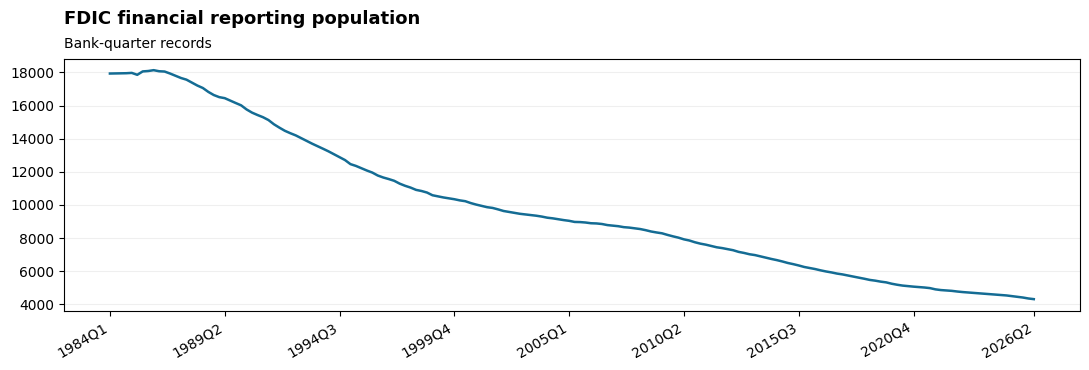

**Finding:** 1984Q1 reports **17,930** banks; 2026Q2 reports **4,313**. The maximum reporting quarter is **1986Q1**. This is reporting coverage, not a bank-failure count.

In [99]:
# 8.1 — Figure 1: observed financial reporting banks per quarter
fig, ax=plt.subplots(figsize=(11,3.8))
ax.plot(range(len(row_summary)),row_summary.bank_records,linewidth=1.8,color='#146c94')
positions=np.linspace(0,len(row_summary)-1,min(9,len(row_summary)),dtype=int)
ax.set_xticks(positions,[row_summary.quarter.iloc[j] for j in positions],rotation=30,ha='right')
ax.set_ylabel('');ax.text(0,1.03,'Bank-quarter records',transform=ax.transAxes,
                         fontsize=10,ha='left',va='bottom')
ax.grid(axis='y',alpha=.2)
ax.set_title('FDIC financial reporting population',loc='left',fontsize=13,fontweight='bold',pad=25)
fig.tight_layout();fig.savefig(RUN/'figures/01_quarterly_record_population.svg',bbox_inches='tight')
plt.show()
initial,ending=int(row_summary.bank_records.iloc[0]),int(row_summary.bank_records.iloc[-1])
display(Markdown(f'**Finding:** {row_summary.quarter.iloc[0]} reports **{initial:,}** banks; '
    f'{row_summary.quarter.iloc[-1]} reports **{ending:,}**. The maximum reporting quarter is '
    f'**{row_summary.loc[row_summary.bank_records.idxmax(),"quarter"]}**. This is reporting '
    'coverage, not a bank-failure count.'))

**Interpretation 8.1 — FDIC Reporting Population**

The FDIC reporting population declined from **17,930 banks in 1984Q1 to 4,313 in 2026Q2**, representing a **75.9% reduction**. This reflects changes in the banking population, including consolidation and institutional exits, rather than bank failures alone. Consequently, longitudinal analysis must account for population changes and the resulting unbalanced panel structure.

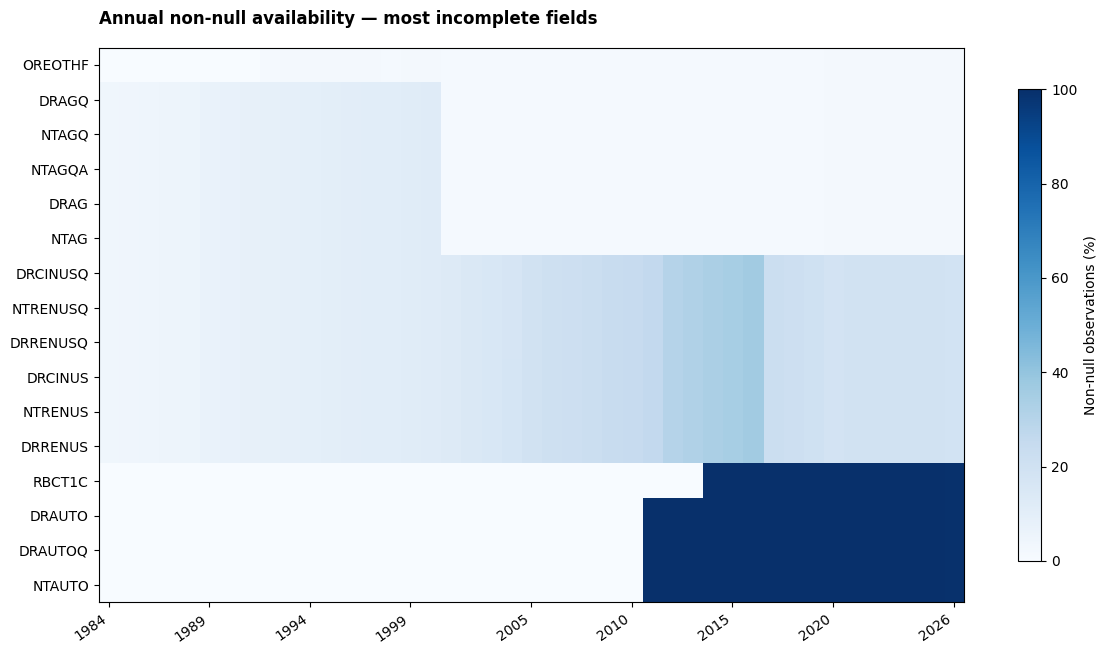

Fields with at least one all-missing historical year: 5 out of 16 plotted fields


In [100]:
# 8.2 — Figure 2: selected field historical coverage heatmap
heat_fields=field_review.sort_values('missing_pct',ascending=False).head(min(16,N_FIELDS)).field.tolist()
yearly=coverage.assign(year=coverage.quarter.str[:4].astype(int))    .groupby(['field','year'],as_index=False).agg(non_null=('non_null','sum'),rows=('rows','sum'))
yearly['coverage_pct']=100*yearly.non_null/yearly.rows.replace(0,np.nan)
heat=yearly.pivot(index='field',columns='year',values='coverage_pct').reindex(heat_fields)
fig,ax=plt.subplots(figsize=(12, max(4,0.29*len(heat_fields)+2)))
im=ax.imshow(heat.values,aspect='auto',vmin=0,vmax=100,cmap='Blues')
ax.set_yticks(range(len(heat_fields)),heat_fields)
indices=np.linspace(0,heat.shape[1]-1,min(9,heat.shape[1]),dtype=int)
ax.set_xticks(indices,[str(heat.columns[i]) for i in indices],rotation=35,ha='right')
ax.set_title('Annual non-null availability — most incomplete fields',loc='left',pad=17,fontweight='bold')
fig.colorbar(im,ax=ax,shrink=.85,label='Non-null observations (%)')
fig.tight_layout();fig.savefig(RUN/'figures/02_field_historical_coverage.svg',bbox_inches='tight')
plt.show()
print('Fields with at least one all-missing historical year:',int(heat.eq(0).any(axis=1).sum()),
      'out of',len(heat_fields),'plotted fields')

**Interpretation 8.2 — Historical Data Availability**

Historical data coverage varies substantially, with **5 of the 16 most incomplete fields** experiencing at least one entirely missing year. Several indicators became available only in later periods, suggesting structural reporting gaps. Therefore, **time-aware feature selection** is necessary to avoid inappropriate imputation and biased historical comparisons.

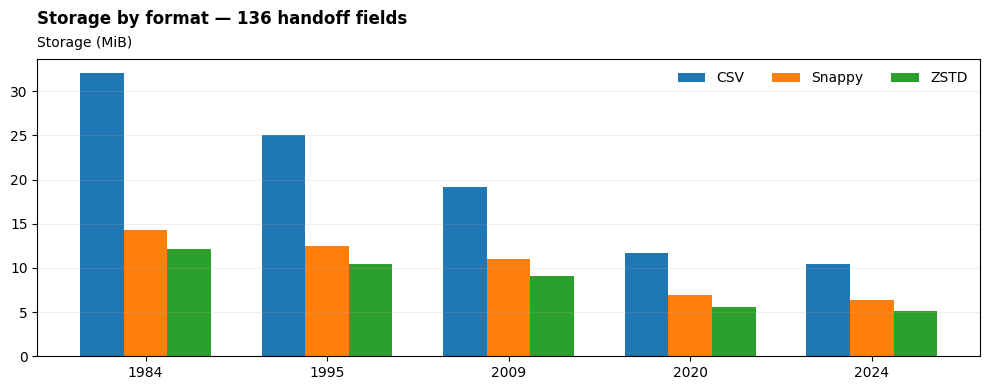

**Finding:** Snappy saves **47.99%** and ZSTD saves **57.01%** versus matched CSV bytes.

In [101]:
# 8.3 — Figure 3: storage footprint by codec (dynamic number of fields)
p=write_summary.pivot(index='year',columns='format',values='file_mib').loc[YEARS]
fig,ax=plt.subplots(figsize=(10,4));width=.24
for j,name in enumerate(FORMAT_NAMES):
    ax.bar(np.arange(len(YEARS))+(j-1)*width,p[name],width,label=name)
ax.set_xticks(np.arange(len(YEARS)),list(map(str,YEARS)))
ax.set_ylabel('');ax.text(0,1.03,'Storage (MiB)',transform=ax.transAxes,
                         fontsize=10,ha='left',va='bottom')
ax.set_title(f'Storage by format — {N_FIELDS} handoff fields',loc='left',pad=25,fontweight='bold')
ax.grid(axis='y',alpha=.2);ax.legend(frameon=False,ncol=3)
fig.tight_layout();fig.savefig(RUN/'figures/03_storage_footprint.svg',bbox_inches='tight')
plt.show()
display(Markdown(f'**Finding:** Snappy saves **{compressed_saving["Snappy"]:.2f}%** and '
                 f'ZSTD saves **{compressed_saving["ZSTD"]:.2f}%** versus matched CSV bytes.'))

**Interpretation 8.3 — Storage Efficiency**

Across five representative years and **136 FDIC fields**, Parquet significantly reduced storage requirements compared with CSV. **Snappy achieved 47.99% space savings (1.92× compression)**, while **ZSTD achieved 57.01% (2.33× compression)**. ZSTD therefore provides superior storage efficiency, saving an additional **9.02 percentage points** compared with Snappy.

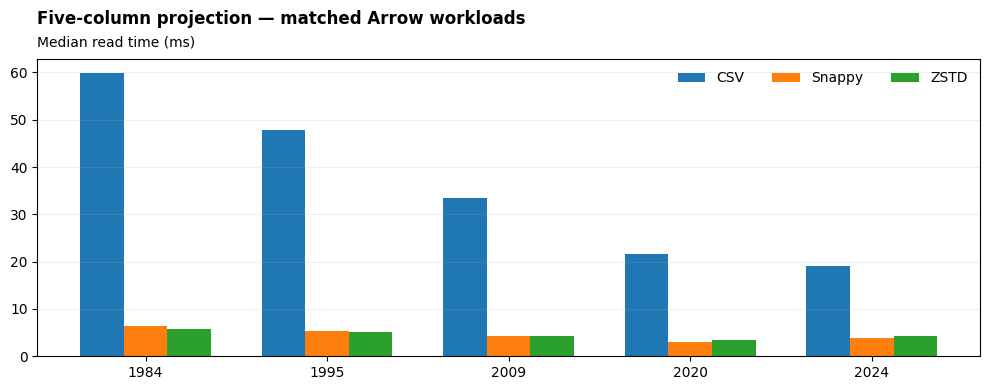

**Finding:** CSV/Snappy speedup ranges **4.88×–9.45×** across sampled years.

In [102]:
# 8.4 — Figure 4: equivalent five-column projection read time
p=read_summary.pivot(index='year',columns='format',values='median_read_ms').loc[YEARS]
fig,ax=plt.subplots(figsize=(10,4));width=.24
for j,name in enumerate(FORMAT_NAMES):
    ax.bar(np.arange(len(YEARS))+(j-1)*width,p[name],width,label=name)
ax.set_xticks(np.arange(len(YEARS)),list(map(str,YEARS)))
ax.set_ylabel('');ax.text(0,1.03,'Median read time (ms)',transform=ax.transAxes,
                         fontsize=10,ha='left',va='bottom')
ax.set_title('Five-column projection — matched Arrow workloads',loc='left',pad=25,fontweight='bold')
ax.grid(axis='y',alpha=.2);ax.legend(frameon=False,ncol=3)
fig.tight_layout();fig.savefig(RUN/'figures/04_projection_read_latency.svg',bbox_inches='tight')
plt.show()
ratio=(p.CSV/p.Snappy)
display(Markdown('**Finding:** CSV/Snappy speedup ranges **'+
                 f'{ratio.min():.2f}×–{ratio.max():.2f}×** across sampled years.'))

**Interpretation 8.4 — Column Projection Performance**

Parquet consistently outperformed CSV when reading five selected columns, with **Snappy achieving 3.58×–9.68× faster reads** across the benchmark years. This demonstrates the advantage of columnar storage for selective financial queries, particularly for feature engineering and machine learning workflows requiring only subsets of the 136 available fields.

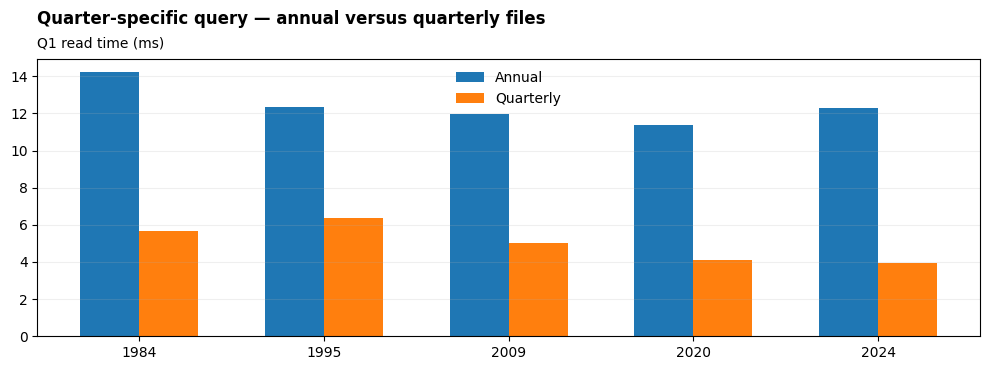

Median storage overhead (%): 12.086


In [103]:
# 8.5 — Figure 5: Q1 annual/quarterly partition latency and footprint comparison
pivot=partition_summary.pivot(index='year',columns='partition',values='read_ms').loc[YEARS]
fig,ax=plt.subplots(figsize=(10,3.8));width=.32
for j,name in enumerate(['Annual','Quarterly']):
    ax.bar(np.arange(len(YEARS))+(j-.5)*width,pivot[name],width,label=name)
ax.set_xticks(np.arange(len(YEARS)),list(map(str,YEARS)))
ax.set_ylabel('');ax.text(0,1.03,'Q1 read time (ms)',transform=ax.transAxes,
                         fontsize=10,ha='left',va='bottom')
ax.set_title('Quarter-specific query — annual versus quarterly files',loc='left',pad=25,fontweight='bold')
ax.grid(axis='y',alpha=.2);ax.legend(frameon=False)
fig.tight_layout();fig.savefig(RUN/'figures/05_partition_pruning.svg',bbox_inches='tight')
plt.show()
print('Median storage overhead (%):',round(float(partition_storage.storage_overhead_pct.median()),3))

**Interpretation 8.5 — Partitioning Trade-off**

Quarterly partitioning achieved approximately **1.85×–2.72× faster Q1-specific queries** than annual partitioning but introduced a **median storage overhead of 12.09%**. Therefore, annual partitioning provides better storage efficiency, while quarterly partitioning benefits time-specific analytical workloads.

**Overall Research Implications**

The empirical findings support three preliminary decisions:

1. **Data Quality:** Apply time-aware missingness analysis before financial feature engineering.
2. **Storage Format:** Adopt Parquet with Snappy as the default analytical format, while retaining ZSTD as a storage-efficient alternative.
3. **Partitioning:** Prioritize annual partitioning for storage efficiency and use quarterly partitioning when selective query performance justifies the additional overhead.

Overall, the results establish a reproducible foundation for subsequent FDIC financial analysis. However, full-panel scalability testing remains necessary before finalizing the storage architecture.

## 9 — Integrity certification, Phase 2 handoff and final scientific conclusion

A complete Phase 1 delivers **(1)** a reproducible history of the source fields requested by Phase 0, **(2)** API and checksum provenance, **(3)** a typed Bronze panel, **(4)** measured storage/query evidence, and **(5)** explicit unresolved issues for Phase 2.

The final cell constructs its conclusion from tables generated *during the current execution*. No inherited record counts, missingness rates or compression percentages are passed off as measurements from this run.

In [104]:
# 9.1 — Global quantitative integrity dashboard
assert verify_phase0_pin(), 'Phase0 artifacts changed after acquisition began'
checks=pd.DataFrame([
    {'check':'Phase0 JSON count equals requested unique codes',
     'passed':N_FIELDS==handoff['n_fields_to_request']==len(set(FIELDS))},
    {'check':'Phase0 selected CSV matches JSON (ordered)',
     'passed':selection.field.astype(str).tolist()==FIELDS},
    {'check':'API count and page-integrity checks across all full-history quarters',
     'passed':len(provenance)==len(QUARTERS) and provenance.all_groups_complete.all()},
    {'check':'Raw unique keys per quarter', 'passed':raw_audit.rows.eq(raw_audit.unique_cert).all()},
    {'check':'Raw source total matches API', 'passed':provenance.raw_rows.eq(provenance.api_total).all()},
    {'check':'All Raw SHA and schema checks', 'passed':raw_audit.status.eq('PASS').all()},
    {'check':'All typed Bronze SHA and schema checks', 'passed':bronze_audit.status.eq('PASS').all()},
    {'check':'Exact Raw/Bronze all-value equivalence', 'passed':full_value_audit.exact_value_equal.all()},
    {'check':'Full Raw/Bronze row reconciliation',
     'passed':int(raw_audit.rows.sum())==int(bronze_audit.rows.sum())},
    {'check':'Every field has coverage accounting', 'passed':len(summary)==N_FIELDS},
    {'check':'Reference raw archives agree with API counts (metadata only)','passed':refs.rows.eq(refs.api_total).all()},
    {'check':'Phase0 input SHA remained pinned through acquisition', 'passed':verify_phase0_pin()},
])
checks.to_csv(RUN/'tables/phase1_integrity_scorecard.csv',index=False)
display(checks)
assert checks.passed.all(), 'Phase1 integrity certification FAILED'
print(f'TECHNICAL ACQUISITION/STORAGE CHECKS: {checks.passed.sum()}/{len(checks)} PASS')
print('API snapshot isolation: NOT CERTIFIED; historical cached page SHA: may be absent')
print('NOT certified here: historical field semantics, event eligibility, label maturity, publication vintage')

,check,passed
0,Phase0 JSON count equals requested unique codes,True
1,Phase0 selected CSV matches JSON (ordered),True
2,API count and page-integrity checks across all...,True
3,Raw unique keys per quarter,True
4,Raw source total matches API,True
5,All Raw SHA and schema checks,True
6,All typed Bronze SHA and schema checks,True
7,Exact Raw/Bronze all-value equivalence,True
8,Full Raw/Bronze row reconciliation,True
9,Every field has coverage accounting,True


TECHNICAL ACQUISITION/STORAGE CHECKS: 12/12 PASS
API snapshot isolation: NOT CERTIFIED; historical cached page SHA: may be absent
NOT certified here: historical field semantics, event eligibility, label maturity, publication vintage


**Interpretation 9.1 — Data Integrity Certification**

All **12 integrity checks passed (12/12 PASS)**, confirming consistency between the Phase 0 field selection and Phase 1 acquisition outputs. The checks verify API completeness, unique bank-quarter keys, SHA-256 integrity, schema consistency, and exact Raw–Bronze reconciliation.

These results provide strong evidence of **data completeness, traceability, and reproducibility** throughout the acquisition and storage pipeline. However, passing these checks does not guarantee the economic validity of individual financial indicators or the predictive performance of subsequent models.

**Conclusion:** Phase 1 satisfies its defined technical integrity requirements and provides a validated data foundation for Phase 2 financial feature engineering.

In [105]:
# 9.2 — Full-history, pinned Phase-2 handoff (no TEST/train/validation labels)
if not verify_phase0_pin():raise RuntimeError('Phase0 artifact drift')
phase2_manifest={'contract_version':'1.0','phase0_contract_hash':CONTRACT,
 'phase0_handoff_source':str(HANDOFF_PATH.relative_to(ROOT)),
 'phase0_handoff_sha256':fd.sha256(HANDOFF_PATH),
 'phase0_scope_source':str(SCOPE_PATH.relative_to(ROOT)),
 'phase0_scope_sha256':fd.sha256(SCOPE_PATH),
 'phase0_artifact_sha256':P0_PIN,'phase0_bundle_status':P0_BUNDLE_STATUS,
 'n_fields_acquired':N_FIELDS,'fields_acquired':FIELDS,
 'source_quarters':QUARTERS,'reporting_end':QUARTERS[-1],
 'modelling_observation_cutoff':None,'model_split_status':'DEFERRED_TO_PHASE5',
 'cohort_selection_owner':'PHASE2_RISK_SET_AND_PHASE5_MODEL_DESIGN',
 'archive_scope_not_model_scope':True,
 'scope':RUN_SCOPE,'rows':int(raw_audit.rows.sum()),
 'annual_bronze_files':len(bronze_audit),
 'raw_path_template':f'data/raw/fdic/financials/contract_{CONTRACT}/REPDTE=YYYYMMDD.parquet',
 'bronze_path_template':f'data/bronze/financials/contract_{CONTRACT}/year=YYYY/financials_YYYY.parquet',
 'reference_snapshot_paths':refs.set_index('endpoint').path.to_dict(),
 'reference_snapshot_sha256':refs.set_index('endpoint').sha256.to_dict(),
 'field_coverage_file':str((RUN/'tables/phase2_field_coverage_flags.csv').relative_to(ROOT)),
 'validation_status':'FULL_SCOPE_PASS' if RUN_SCOPE=='full' else 'PILOT_SCOPE_PASS_ONLY',
 'validation_status_scope':'TECHNICAL_ACQUISITION_STORAGE_NOT_LABEL_VALIDATION',
 'pagination_snapshot_isolation':'NOT_PROVEN',
 'api_page_sha_evidence_status':'RECORDED_ALL' if PAGE_EVIDENCE_COMPLETE else 'PARTIAL_OR_LEGACY_NOT_VERIFIABLE',
 'to_do_phase2':['validate source unit, release-vintage and stock/YTD semantics',
  'audit missingness and continuity over all bank-quarters',
  'build failure/competing event registry, resolve censoring and 4Q maturity',
  'DO NOT assign train/validation/test using Phase1 archival controls'],
 'created_utc':fd.utcnow()}
if RUN_SCOPE=='full' and (len(QUARTERS)!=170 or QUARTERS[-1]!='2026Q2'):
    raise ValueError('Refusing FULL_SCOPE_PASS for partial source quarters')
manifest_path=RUN/'reports/phase1_to_phase2_handoff.json'
manifest_path.write_text(json.dumps(phase2_manifest,indent=2,ensure_ascii=False),encoding='utf-8')
print('Phase 2 handoff:',manifest_path)
print('Acquisition:',RUN_SCOPE,'| fields:',N_FIELDS,'| full-history bank-quarter rows:',phase2_manifest['rows'])

Phase 2 handoff: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase1_from_phase0\runs\20261123T153505Z_b669ff\reports\phase1_to_phase2_handoff.json
Acquisition: full | fields: 136 | full-history bank-quarter rows: 1682616


**Check 9.2.** All field codes in the Phase 2 handoff derive from `fields_to_request` in Phase 0. No failure flag, reporting-date leakage variable or feature-selection output is inserted. `PILOT_SCOPE_PASS_ONLY` prevents accidental claims of complete coverage.

In [106]:
# 9.3 — Measured closing conclusion (Markdown + standalone audited report)
missing_total=int(summary.missing.sum())
expected_total=int(summary.expected.sum())
missing_rate=100*missing_total/expected_total if expected_total else float('nan')
engine_finding='; '.join(f'{r.engine}: {r.median_seconds:.3f}s' for r in engine_summary.itertuples())
lines=[
 '# PHASE 1 — FINAL REPRODUCIBLE CONCLUSION',
 f'**Run:** `{RUN_ID}` · **Contract:** `{CONTRACT}` · **Status:** `{phase2_manifest["validation_status"]}`',
 '',
 '## 1. Acquisition scope and completeness',
 f'Phase 0 evaluated **{handoff["all_api_field_count"]:,} official FDIC codes** and handed off '
 f'**{N_FIELDS:,} distinct Financials fields** (including keys). Phase 1 acquired or verified '
 f'**{len(QUARTERS):,} quarters**, **{int(raw_audit.rows.sum()):,} bank-quarter records** '
 f'from `{QUARTERS[0]}` through `{QUARTERS[-1]}`. Field batching required '
 f'**{len(GROUPS)} API field groups/quarter**. All source groups agreed on keys and `meta.total`.',
 '', '## 2. Integrity and historical coverage',
 f'**{int(checks.passed.sum())}/{len(checks)} integrity controls PASS**; '
 f'**{len(bronze_audit)} annual Bronze Parquet files** are reconciled to Raw with full-value equivalence. '
 f'The all-field, all-row observed missing proportion is **{missing_rate:.2f}%**. '
 f'**{int(field_review.all_missing.sum())} fields** have no data within this acquisition scope; '
 f'**{int(field_review.missing_pct.ge(50).sum())} fields** have at least 50% missingness (review flags only).',
 '', '## 3. Measured storage, query and processing tradeoffs',
 f'On years **{", ".join(map(str,YEARS))}** and **{N_FIELDS} fields**, '
 f'Snappy reduced pooled storage by **{compressed_saving["Snappy"]:.2f}%** versus CSV '
 f'and ZSTD by **{compressed_saving["ZSTD"]:.2f}%**. '
 f'Median Snappy write time across sampled years was **{pooled_write["Snappy"]:.2f} ms**. '
 f'Query timing and annual/quarterly comparisons are reported separately in their measured tables. '
 f'Engine wall-clock medians: **{engine_finding}**.',
 '', '## 4. Decision and limitations',
 '**Technical decision:** preserve immutable, provenance-stamped quarterly Raw and '
 'contract-versioned annual Snappy Bronze as the operational default; use ZSTD or quarterly '
 'partitioning only when measured workload benefits justify the trade-offs. '
 'This decision is limited to the tested years, codec settings and host environment.',
 '**Research limitation:** Phase 0 field priority scores are not predictive importance. '
 'The historical availability of some new FDIC fields is uneven; source-unit comparability, '
 'failure event labels, future availability and model leakage remain pending for Phase 2. '
 'No claims are made about PR-AUC, bank-failure recall or model effectiveness.',
 '', '## 5. Phase 2 transition',
 f'Use `{manifest_path.relative_to(ROOT)}` and field coverage flags to build audited '
 'ratios, temporal features and failure labels under the **2025Q2** observation cutoff '
 'and future-only held-out evaluation.',
]
report='\n\n'.join(lines)+'\n'
report_path=RUN/'reports/phase1_final_evidence_report.md'
report_path.write_text(report,encoding='utf-8')
display(Markdown(report))
print('Final evidence report saved:',report_path)

# PHASE 1 — FINAL REPRODUCIBLE CONCLUSION

**Run:** `20261123T153505Z_b669ff` · **Contract:** `a1cd7440e6a09ca8` · **Status:** `FULL_SCOPE_PASS`



## 1. Acquisition scope and completeness

Phase 0 evaluated **2,378 official FDIC codes** and handed off **136 distinct Financials fields** (including keys). Phase 1 acquired or verified **170 quarters**, **1,682,616 bank-quarter records** from `1984Q1` through `2026Q2`. Field batching required **5 API field groups/quarter**. All source groups agreed on keys and `meta.total`.



## 2. Integrity and historical coverage

**12/12 integrity controls PASS**; **43 annual Bronze Parquet files** are reconciled to Raw with full-value equivalence. The all-field, all-row observed missing proportion is **21.72%**. **0 fields** have no data within this acquisition scope; **29 fields** have at least 50% missingness (review flags only).



## 3. Measured storage, query and processing tradeoffs

On years **1984, 1995, 2009, 2020, 2024** and **136 fields**, Snappy reduced pooled storage by **47.99%** versus CSV and ZSTD by **57.01%**. Median Snappy write time across sampled years was **412.55 ms**. Query timing and annual/quarterly comparisons are reported separately in their measured tables. Engine wall-clock medians: **Pandas: 0.896s; Polars: 0.090s**.



## 4. Decision and limitations

**Technical decision:** preserve immutable, provenance-stamped quarterly Raw and contract-versioned annual Snappy Bronze as the operational default; use ZSTD or quarterly partitioning only when measured workload benefits justify the trade-offs. This decision is limited to the tested years, codec settings and host environment.

**Research limitation:** Phase 0 field priority scores are not predictive importance. The historical availability of some new FDIC fields is uneven; source-unit comparability, failure event labels, future availability and model leakage remain pending for Phase 2. No claims are made about PR-AUC, bank-failure recall or model effectiveness.



## 5. Phase 2 transition

Use `outputs\phase1_from_phase0\runs\20261123T153505Z_b669ff\reports\phase1_to_phase2_handoff.json` and field coverage flags to build audited ratios, temporal features and failure labels under the **2025Q2** observation cutoff and future-only held-out evaluation.


Final evidence report saved: C:\học tập\kì 7\Big data\Final\Bản nháp\outputs\phase1_from_phase0\runs\20261123T153505Z_b669ff\reports\phase1_final_evidence_report.md


### Reproducibility notes

- This notebook requires the genuine **Phase-0 handoff artifacts** in `docs/` to run
- Uploaded Phase-0 notebook Section 9 cells had no saved execution counts. That does not prove they have not been run elsewhere; use the preflight cell to inspect the actual project files.
- Before downloading all historical records, keep `RUN_SCOPE='pilot'` to validate the 2023Q1–2023Q4 path.
- Raw and Bronze from older field contracts remain untouched.
- An offline test of the helper functions is not a live FDIC API validation; check external availability and dependencies in your own project environment.

### Final audit interpretation

**Phase 1 succeeds when the measured evidence above passes; it is not judged by reproducing last semester's 48-field storage numbers.** Phase 0 selected the variable *acquisition scope*; Phase 1 verified those data can be acquired, preserved and processed; Phase 2 will determine whether each indicator is analytically usable and adds out-of-time predictive value.

**Required deliverables:** quarterly Raw & manifests, annual Bronze & manifests, `raw_api_pagination_provenance.csv`, `phase2_field_coverage_flags.csv`, benchmark CSVs, five SVG figures, final evidence report and `phase1_to_phase2_handoff.json`.

**Documentation:** [FDIC BankFind API](https://api.fdic.gov/banks/docs/) · [FDIC Financials YAML](https://api.fdic.gov/banks/docs/risview_properties.yaml) · [Guyon & Elisseeff (2003), variable selection](https://www.jmlr.org/papers/v3/guyon03a.html).